# Análise de risco de crédito: EDA, features e target

Este notebook percorre as quatro bases, documenta as features criadas em cada uma, define o target de inadimplência e termina com a **base final de modelagem**.

| Seção | Pergunta que responde |
|---|---|
| 1. Cadastro | Quem é o cliente? |
| 2. Submissão | O que ele está pedindo agora? |
| 3. Histórico de empréstimos | Como foram os pedidos anteriores? |
| 4. Histórico de parcelas | Como ele pagou no passado? |
| 5. Target | O que é "inadimplente" e por quê? |
| 6. Base final | Treino (com target) e score (submissão), lado a lado |

O código das transformações fica em dois módulos:

- `feature_engineering.py` → classe `FeatureEngineering`
- `target_engineering.py` → classe `TargetEngineering`

**Princípio que guia tudo: point-in-time.** O modelo vai pontuar o pedido *no momento da solicitação*. Então cada linha de treino só pode usar informação que existia na data daquele pedido (`data_decisao`). Qualquer coisa posterior, como liberação, encerramento ou parcelas futuras, é vazamento de informação.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from dataviz import dataviz
from feature_engineering import FeatureEngineering
from target_engineering import TargetEngineering, TARGET_PRINCIPAL

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)

# Paleta e estilo dos graficos novos (azul, laranja, aqua; grid discreto)
AZUL, LARANJA, AQUA, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold",
})

In [2]:
base_cadastral = pd.read_parquet("data/base_cadastral.parquet")
base_submissao = pd.read_parquet("data/base_submissao.parquet")
hist_emprestimos = pd.read_parquet("data/historico_emprestimos.parquet")
hist_parcelas = pd.read_parquet("data/historico_parcelas.parquet")
dict_dados = pd.read_csv("data/dicionario_dados.csv", sep=";")

for nome, tabela in {
    "base_cadastral": base_cadastral,
    "base_submissao": base_submissao,
    "hist_emprestimos": hist_emprestimos,
    "hist_parcelas": hist_parcelas,
}.items():
    print(f"{nome:18s}: {tabela.shape[0]:>9,} linhas x {tabela.shape[1]} colunas")

base_cadastral    :    40,000 linhas x 16 colunas
base_submissao    :    40,000 linhas x 8 colunas
hist_emprestimos  :   186,890 linhas x 37 colunas
hist_parcelas     : 1,390,978 linhas x 8 colunas


## 1. Cadastro do cliente

Uma linha por cliente com o contexto socioeconômico declarado. Primeiro checamos cobertura e consistência; depois criamos features simples, sem imputar valores.

In [3]:
dict_dados[dict_dados["base"] == "base_cadastral"]

,base,coluna,descricao
0,base_cadastral,id_cliente,Identificador único do cliente
1,base_cadastral,sexo,Sexo do cliente (M ou F)
2,base_cadastral,data_nascimento,Data de nascimento do cliente
3,base_cadastral,qtd_filhos,Quantidade de filhos declarados
4,base_cadastral,qtd_membros_familia,Quantidade total de membros da família
5,base_cadastral,renda_anual,Renda total anual declarada pelo cliente
6,base_cadastral,tipo_renda,"Tipo de fonte de renda (trabalho, pensão, apos..."
7,base_cadastral,ocupacao,Ocupação profissional do cliente
8,base_cadastral,tipo_organizacao,Tipo de empresa onde o cliente trabalha
9,base_cadastral,nivel_educacao,Nível de escolaridade alcançado


In [4]:
print("Dimensões:", base_cadastral.shape)
print("IDs de cliente duplicados:", int(base_cadastral["id_cliente"].duplicated().sum()))
print("Clientes sem ocupação:", int(base_cadastral["ocupacao"].isna().sum()))
print("tipo_organizacao == XNA:", int(base_cadastral["tipo_organizacao"].eq("XNA").sum()))
print("Membros familiares não positivos:", int((base_cadastral["qtd_membros_familia"] <= 0).sum()))

Dimensões: (40000, 16)
IDs de cliente duplicados: 0
Clientes sem ocupação: 12676
tipo_organizacao == XNA: 7383
Membros familiares não positivos: 0


### Features criadas no cadastro

| Feature | Cálculo | Por que importa |
|---|---|---|
| `renda_per_capita` | `renda_anual / qtd_membros_familia` | Renda disponível por pessoa: R$ 150 mil para 1 pessoa ≠ para 5 |
| sentinelas → nulo | `XNA`, `XAP`, `Unknown`… viram `NaN` | São códigos de "não informado", não categorias reais |
| `idade` *(na base final)* | `data_referencia − data_nascimento` | Calculada **na data do pedido**, não hoje. Por isso não é criada aqui |
| `parcela_sobre_renda` *(na base final)* | `valor_parcela / renda_anual` | Quanto da renda a nova parcela consome (comprometimento) |
| `credito_sobre_renda` *(na base final)* | `valor_credito / renda_anual` | Tamanho da dívida relativo à renda |

As duas últimas cruzam cadastro e pedido, então só existem depois do merge na seção 6. Elas dividem pela renda **como declarada**, sem converter para mensal: a seção 2 mostra que a unidade de `renda_anual` não é confiável.

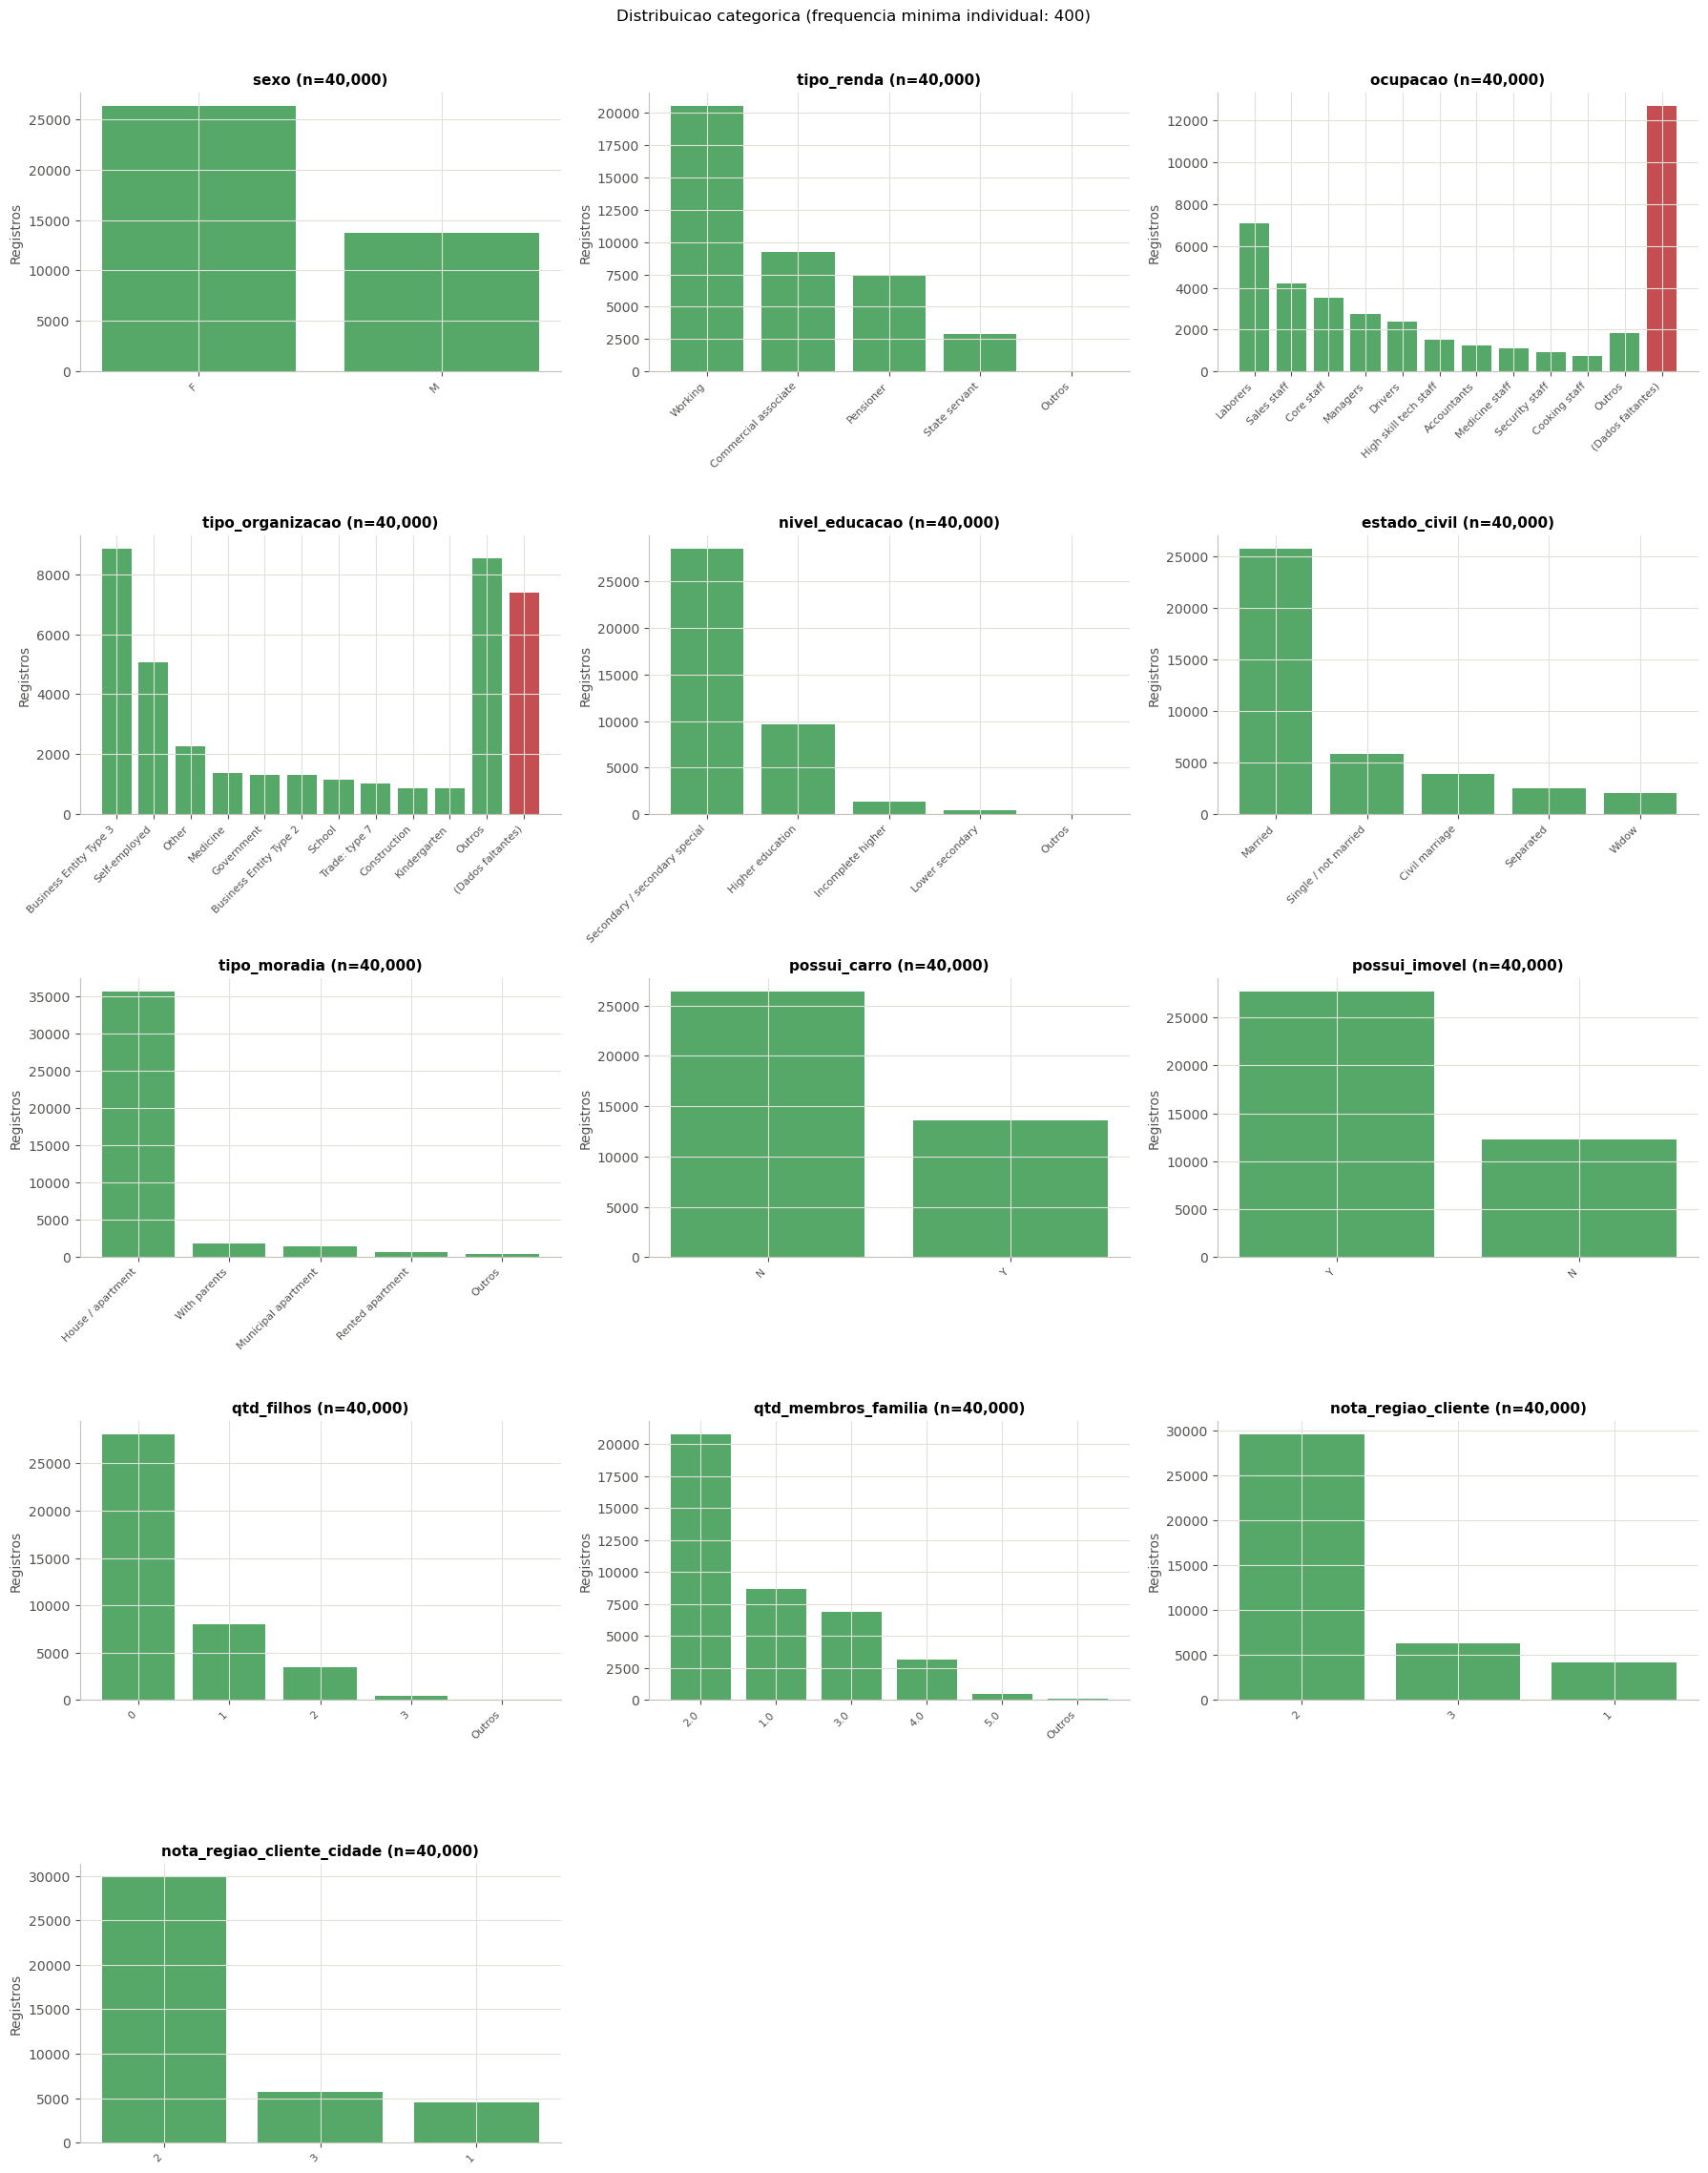

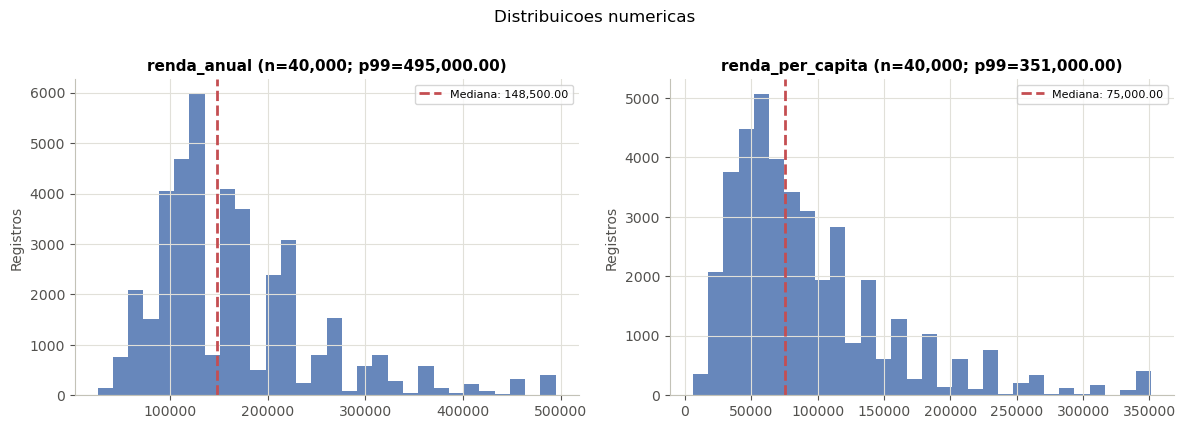

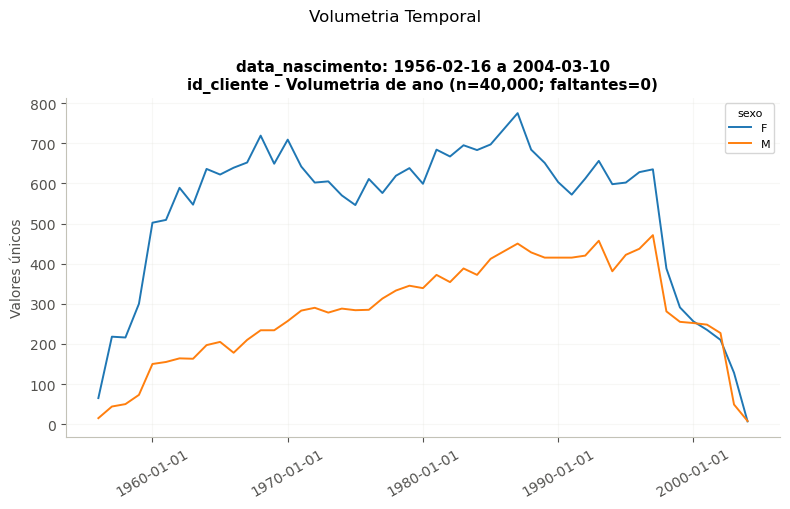

In [5]:
cadastro_fe = FeatureEngineering.enriquecer_cadastro(base_cadastral)

visualizacoes_cadastro = dataviz(
    dataset=cadastro_fe,
    feature_cat=[
        "sexo", "tipo_renda", "ocupacao", "tipo_organizacao", "nivel_educacao",
        "estado_civil", "tipo_moradia", "possui_carro", "possui_imovel",
        "qtd_filhos", "qtd_membros_familia", "nota_regiao_cliente", "nota_regiao_cliente_cidade",
    ],
    feature_num=["renda_anual", "renda_per_capita"],
    feature_data=["data_nascimento"],
    feature_volume="id_cliente",
    feature_data_groupby="sexo",
    data_frequency="A",
    volume_aggregation="nunique",
    min_category_count=400,
)
plt.show()


**Leitura do cadastro.**

- `id_cliente` é único.
- `ocupacao` falta em ~32% dos clientes e `tipo_organizacao` usa `XNA` em 7.383 linhas, ambos agora tratados como nulo.
- A renda tem cauda longa: a mediana fica bem abaixo da média. Para modelos lineares, vale usar log ou faixas.
- `renda_per_capita` reduz a renda de quem tem família grande e separa clientes de mesma renda total.

**A ausência de ocupação é aleatória?** Se os nulos se concentram num tipo de renda, a ausência carrega informação e deve virar uma categoria própria ("Não informado") em vez de ser imputada.

,clientes,ocupacao_ausente_pct
tipo_renda,,
Working,20502,15.4
Commercial associate,9251,17.4
Pensioner,7380,100.0
State servant,2858,18.1
Unemployed,3,100.0
Maternity leave,3,0.0
Student,2,0.0
Businessman,1,0.0


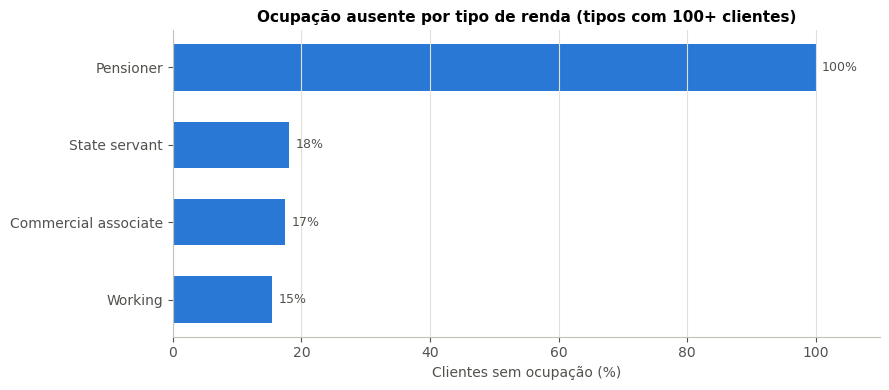

In [6]:
ausencia_ocupacao = (
    cadastro_fe.assign(ocupacao_ausente=cadastro_fe["ocupacao"].isna())
    .groupby("tipo_renda")
    .agg(clientes=("id_cliente", "size"), ocupacao_ausente_pct=("ocupacao_ausente", "mean"))
    .sort_values("clientes", ascending=False)
)
ausencia_ocupacao["ocupacao_ausente_pct"] *= 100
display(ausencia_ocupacao.round(1))

fig, ax = plt.subplots(figsize=(9, 4))
ordem = ausencia_ocupacao.query("clientes >= 100").sort_values("ocupacao_ausente_pct")
ax.barh(ordem.index, ordem["ocupacao_ausente_pct"], color=AZUL, height=0.6)
for y, v in enumerate(ordem["ocupacao_ausente_pct"]):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9, color="#52514e")
ax.set_xlabel("Clientes sem ocupação (%)")
ax.set_title("Ocupação ausente por tipo de renda (tipos com 100+ clientes)")
ax.set_xlim(0, 110)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Leitura.** A ausência de ocupação não é aleatória: está quase toda nos **aposentados (Pensioner)**, para quem "ocupação" não se aplica. Por isso, na modelagem, `ocupacao` nula deve virar uma categoria própria, e não ser imputada pela moda.

## 2. Solicitação atual (base de submissão)

Uma linha por cliente: é o pedido que o modelo vai pontuar. Daqui saem as features do **pedido**, as mesmas que existem no histórico de empréstimos para o treino.

In [7]:
dict_dados[dict_dados["base"] == "base_submissao"]

,base,coluna,descricao
16,base_submissao,id_cliente,Identificador único do cliente
17,base_submissao,data_solicitacao,Data em que o contrato mais recente foi solici...
18,base_submissao,dia_semana_solicitacao,Dia da semana em que o pedido foi iniciado
19,base_submissao,hora_solicitacao,Hora do dia em que a solicitação foi realizada
20,base_submissao,tipo_contrato,Tipo de contrato solicitado (ex: crédito pesso...
21,base_submissao,valor_credito,Valor total do crédito solicitado
22,base_submissao,valor_bem,"Valor do bem financiado, quando aplicável"
23,base_submissao,valor_parcela,Valor da parcela periódica estimada para pagam...


In [8]:
print("Dimensões:", base_submissao.shape)
print("IDs de cliente duplicados:", int(base_submissao["id_cliente"].duplicated().sum()))
print("Período:", base_submissao["data_solicitacao"].min(), "a", base_submissao["data_solicitacao"].max())
print("Nulos:", base_submissao.isna().sum()[lambda s: s > 0].to_dict())

Dimensões: (40000, 8)
IDs de cliente duplicados: 0
Período: 2025-02-04 a 2025-02-24
Nulos: {'valor_bem': 24, 'valor_parcela': 4}


### Features criadas no pedido

São calculadas igualmente na submissão e no histórico (`FeatureEngineering.enriquecer_pedido`):

| Feature | Cálculo | Por que importa |
|---|---|---|
| `parcela_sobre_credito` | `valor_parcela / valor_credito` | Fração da dívida paga por mês; ≈ 1/prazo |
| `prazo_estimado_meses` | `valor_credito / valor_parcela` | Prazo implícito (sem juros). Prazos longos acumulam mais risco |
| `credito_sobre_bem` | `valor_credito / valor_bem` | Acima de 1 indica seguro ou tarifas financiados junto |

Denominador zero ou nulo gera `NaN`, nunca infinito.

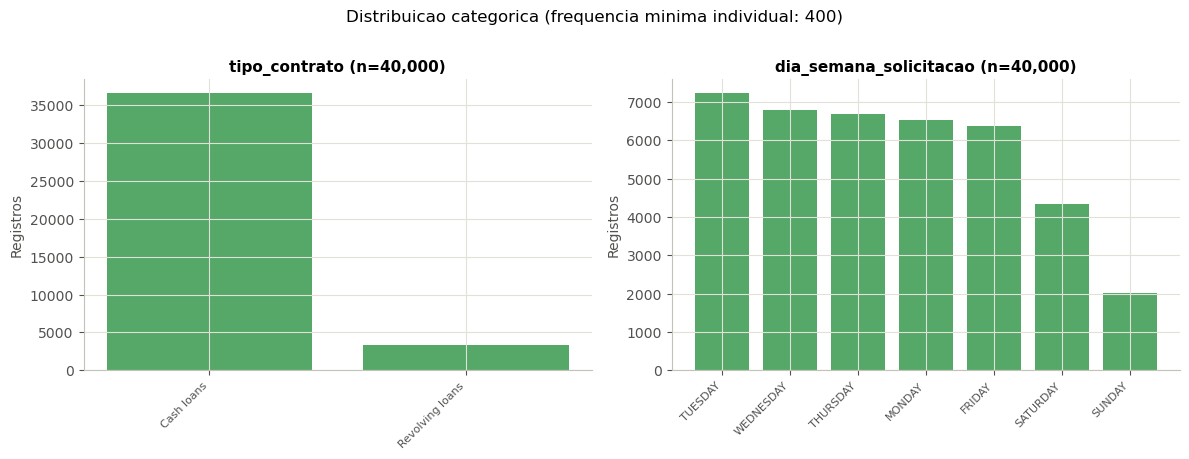

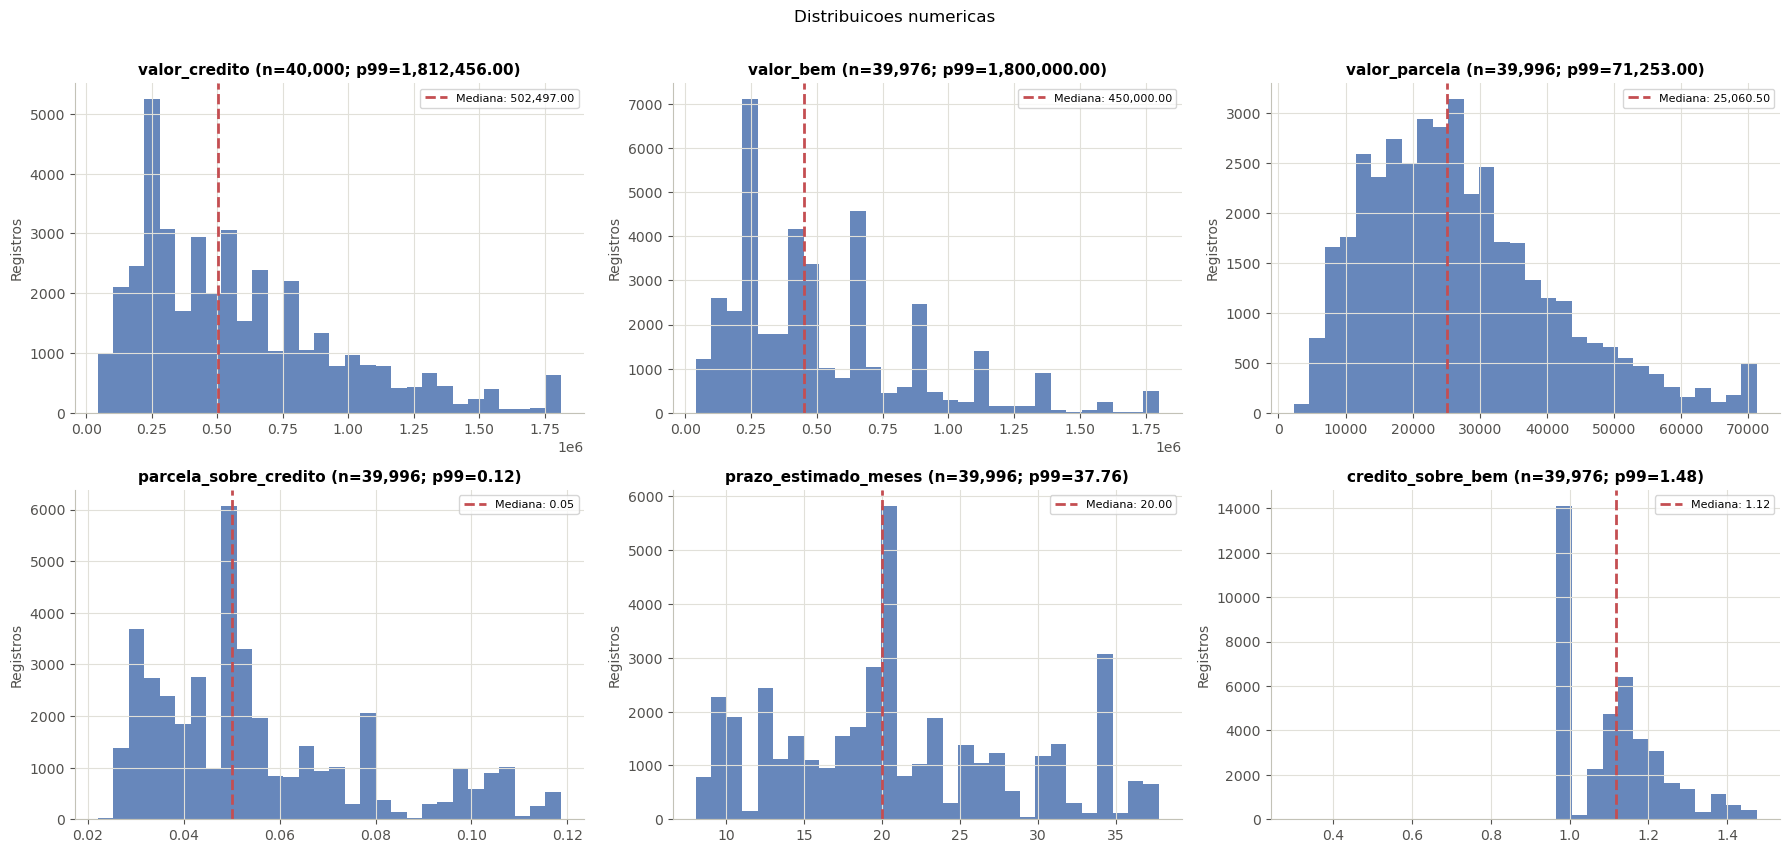

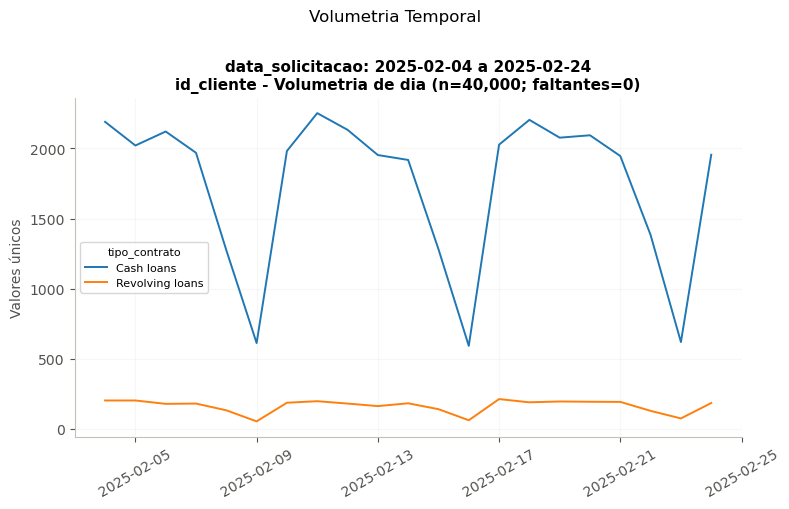

In [9]:
submissao_fe = FeatureEngineering.enriquecer_pedido(base_submissao)

visualizacoes_submissao = dataviz(
    dataset=submissao_fe,
    feature_cat=["tipo_contrato", "dia_semana_solicitacao"],
    feature_num=[
        "valor_credito", "valor_bem", "valor_parcela",
        "parcela_sobre_credito", "prazo_estimado_meses", "credito_sobre_bem",
    ],
    feature_data=["data_solicitacao"],
    feature_volume="id_cliente",
    feature_data_groupby="tipo_contrato",
    data_frequency="D",
    volume_aggregation="nunique",
    min_category_count=400,
)
plt.show()

**Leitura da solicitação.**

- Os pedidos cobrem só fevereiro de 2025 (de 04/02 a 24/02).
- 91,5% são `Cash loans`; o restante é `Revolving loans`.
- Poucos nulos: 24 em `valor_bem` e 4 em `valor_parcela`.
- `prazo_estimado_meses` concentra-se em ~20 meses.
- `credito_sobre_bem` fica tipicamente em ~1,12: o crédito costuma superar o valor do bem, o que é coerente com seguro financiado.

**A renda é mesmo anual?** O dicionário diz que `renda_anual` é a renda anual. Se for, dividir por 12 dá a renda mensal, e a parcela deveria ser uma fração dela.

In [10]:
pedido_renda = base_submissao.merge(base_cadastral[["id_cliente", "renda_anual"]], on="id_cliente")
razao_mensal = pedido_renda["valor_parcela"] / (pedido_renda["renda_anual"] / 12)
razao_direta = pedido_renda["valor_parcela"] / pedido_renda["renda_anual"]
print(f"Parcela / (renda_anual / 12): mediana {razao_mensal.median():.0%}, "
      f"{(razao_mensal > 1).mean():.0%} dos pedidos com parcela maior que a 'renda mensal'")
print(f"Parcela / renda_anual:        mediana {razao_direta.median():.0%}")

Parcela / (renda_anual / 12): mediana 195%, 89% dos pedidos com parcela maior que a 'renda mensal'
Parcela / renda_anual:        mediana 16%


**Leitura.** Se a renda fosse anual, a parcela mediana consumiria ~195% da renda mensal, e a maioria dos pedidos teria parcela maior que o salário. Isso não é plausível para crédito concedido. Já `parcela / renda_anual` fica em ~16%, um comprometimento típico, o que sugere que a coluna guarda, na verdade, a renda **mensal**. Como não dá para confirmar, as features de comprometimento dividem pela renda **como declarada** (`parcela_sobre_renda`, `credito_sobre_renda`). Para o modelo isso não muda nada (é a mesma ordenação), mas evita afirmar uma unidade errada. É um ponto a validar com o banco.

**A submissão se parece com o histórico de treino?** Esta é a pergunta mais importante antes de modelar. O modelo aprende com os contratos aprovados do histórico, mas vai ser aplicado na submissão.

,Histórico aprovado,Submissão
tipo_contrato,,
Cash loans,30.0,91.5
Consumer loans,60.6,0.0
Revolving loans,9.4,8.5


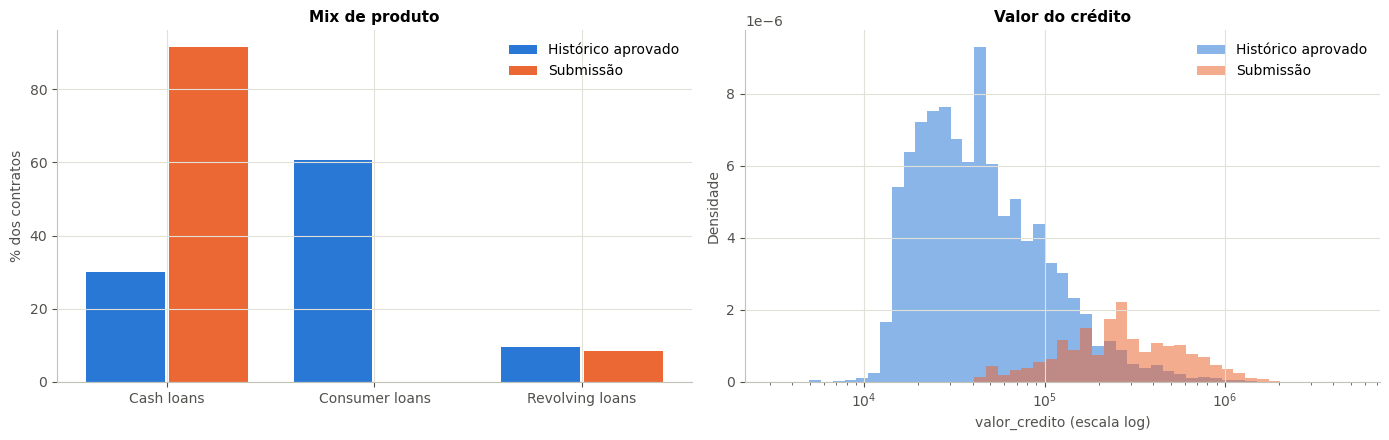

Mediana valor_credito: histórico 101,880 | submissão 502,497


In [11]:
aprovados = hist_emprestimos[hist_emprestimos["status_contrato"] == "Approved"]

mix = pd.DataFrame({
    "Histórico aprovado": aprovados["tipo_contrato"].value_counts(normalize=True),
    "Submissão": base_submissao["tipo_contrato"].value_counts(normalize=True),
}).fillna(0).mul(100)
display(mix.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(mix))
axes[0].bar(x - 0.2, mix["Histórico aprovado"], width=0.38, color=AZUL, label="Histórico aprovado")
axes[0].bar(x + 0.2, mix["Submissão"], width=0.38, color=LARANJA, label="Submissão")
axes[0].set_xticks(x, mix.index)
axes[0].set_ylabel("% dos contratos")
axes[0].set_title("Mix de produto")
axes[0].legend(frameon=False)

bins = np.logspace(3.5, 6.7, 50)
axes[1].hist(aprovados["valor_credito"].dropna(), bins=bins, density=True, color=AZUL, alpha=0.55, label="Histórico aprovado")
axes[1].hist(base_submissao["valor_credito"], bins=bins, density=True, color=LARANJA, alpha=0.55, label="Submissão")
axes[1].set_xscale("log")
axes[1].set_xlabel("valor_credito (escala log)")
axes[1].set_ylabel("Densidade")
axes[1].set_title("Valor do crédito")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

print("Mediana valor_credito: histórico", f"{aprovados['valor_credito'].median():,.0f}",
      "| submissão", f"{base_submissao['valor_credito'].median():,.0f}")

**Leitura: há mudança de população.**

- O histórico é dominado por `Consumer loans` (financiamento de bens, 60%), um produto que **não aparece** na submissão.
- Os pedidos novos são ~5x maiores em valor.

Consequências para a modelagem:

1. `tipo_contrato` precisa entrar como feature.
2. A performance deve ser validada separadamente em `Cash loans`, que é o produto da submissão.
3. Features relativas (parcela/renda, crédito/renda) generalizam melhor entre produtos do que valores absolutos.

## 3. Histórico de empréstimos

Uma linha por pedido anterior, com qualquer desfecho: aprovado, recusado, cancelado ou oferta não usada. Esta base tem dois papéis:

1. **Fonte de features:** quantos pedidos o cliente fez antes, quantos foram recusados, etc.
2. **População de treino:** os contratos aprovados são as linhas que recebem target.

Várias colunas (liberação, vencimentos, encerramento) só existem **depois** da decisão. Elas ajudam na EDA e na construção do target, mas não podem ser preditoras.

In [12]:
dict_dados[dict_dados["base"] == "historico_emprestimos"]

,base,coluna,descricao
24,historico_emprestimos,id_contrato,Identificador único do contrato de empréstimo
25,historico_emprestimos,id_cliente,Identificador do cliente associado ao contrato
26,historico_emprestimos,tipo_contrato,"Tipo de contrato (crédito pessoal, rotativo, e..."
27,historico_emprestimos,status_contrato,"Status final do contrato (aprovado, recusado, ..."
28,historico_emprestimos,data_decisao,Data em que o contrato foi analisado e aprovad...
29,historico_emprestimos,data_liberacao,Data em que o crédito foi liberado
30,historico_emprestimos,data_primeiro_vencimento,Data prevista para o vencimento da primeira pa...
31,historico_emprestimos,data_ultimo_vencimento_original,Data original prevista para a última parcela
32,historico_emprestimos,data_ultimo_vencimento,Data final revisada da última parcela
33,historico_emprestimos,data_encerramento,Data em que o contrato foi encerrado (por quit...


In [13]:
print("Dimensões:", hist_emprestimos.shape)
print("IDs de contrato duplicados:", int(hist_emprestimos["id_contrato"].duplicated().sum()))
print("Mediana de contratos por cliente:", hist_emprestimos.groupby("id_cliente")["id_contrato"].nunique().median())
display(hist_emprestimos["status_contrato"].value_counts(dropna=False).to_frame("contratos"))

nulos = (hist_emprestimos.isna().mean() * 100).sort_values(ascending=False)
print("Campos com mais ausências (%):")
display(nulos[nulos > 0].head(12).round(1).to_frame("percentual_nulo"))

Dimensões: (186890, 37)
IDs de contrato duplicados: 0
Mediana de contratos por cliente: 4.0


,contratos
status_contrato,
Approved,116182
Canceled,35767
Refused,32108
Unused offer,2833


Campos com mais ausências (%):


,percentual_nulo
taxa_juros_padrao,99.7
taxa_juros_promocional,99.7
data_liberacao,96.2
data_encerramento,53.9
percentual_entrada,53.6
valor_entrada,53.6
data_ultimo_vencimento,53.0
acompanhantes_cliente,49.3
data_ultimo_vencimento_original,45.9
data_primeiro_vencimento,42.7


In [14]:
liberacao_ausente = (
    hist_emprestimos.assign(liberacao_ausente=hist_emprestimos["data_liberacao"].isna())
    .groupby("status_contrato")["liberacao_ausente"].mean().mul(100)
)
print("data_liberacao ausente por status (%):")
display(liberacao_ausente.round(1).to_frame())

data_liberacao ausente por status (%):


,liberacao_ausente
status_contrato,
Approved,93.9
Canceled,100.0
Refused,100.0
Unused offer,100.0


A data de liberação falta em 100% dos cancelados e recusados, o que é esperado. Mas também falta em **94% dos aprovados**, então não serve como início do contrato. A alternativa é a `data_decisao`, desde que o intervalo até o primeiro vencimento seja estável, como mostra a próxima célula.

### Features criadas no histórico de empréstimos

`FeatureEngineering.enriquecer_emprestimos` mantém uma linha por contrato:

| Feature | Cálculo | Uso |
|---|---|---|
| `parcela_sobre_credito`, `prazo_estimado_meses`, `credito_sobre_bem` | iguais às do pedido | Preditoras (existem na submissão) |
| `solicitado_sobre_credito` | `valor_solicitado / valor_credito` | EDA: quanto do pedido foi atendido |
| `entrada_sobre_bem` | `valor_entrada / valor_bem` | EDA: entrada como % do bem |
| `dias_decisao_ate_liberacao` | `data_liberacao − data_decisao` | EDA (pós-decisão) |
| `duracao_original_dias` | último − primeiro vencimento original | EDA (pós-decisão) |

Na base final, esta tabela vira features **agregadas por cliente** (`hist_n_pedidos`, `hist_n_recusados`, `hist_taxa_recusa`, …), sempre olhando só para pedidos anteriores ao corte. Os detalhes estão na seção 6.

In [15]:
emprestimos_fe = FeatureEngineering.enriquecer_emprestimos(hist_emprestimos)

inconsistencias = pd.Series({
    "primeiro vencimento antes da liberação": int((emprestimos_fe["data_primeiro_vencimento"] < emprestimos_fe["data_liberacao"]).sum()),
    "encerramento antes da liberação": int((emprestimos_fe["data_encerramento"] < emprestimos_fe["data_liberacao"]).sum()),
    "primeiro vencimento antes da decisão": int((emprestimos_fe["data_primeiro_vencimento"] < emprestimos_fe["data_decisao"]).sum()),
}, name="contratos").to_frame()
display(inconsistencias)

aprovados_fe = emprestimos_fe[emprestimos_fe["status_contrato"] == "Approved"].copy()
aprovados_fe["dias_decisao_ate_1o_vencimento"] = (
    aprovados_fe["data_primeiro_vencimento"] - aprovados_fe["data_decisao"]
).dt.days
print("Dias entre decisão e 1º vencimento (aprovados):")
display(
    aprovados_fe.groupby("tipo_contrato")["dias_decisao_ate_1o_vencimento"]
    .describe(percentiles=[0.25, 0.5, 0.75])[["count", "25%", "50%", "75%"]]
)

,contratos
primeiro vencimento antes da liberação,6
encerramento antes da liberação,2
primeiro vencimento antes da decisão,0


Dias entre decisão e 1º vencimento (aprovados):


,count,25%,50%,75%
tipo_contrato,,,,
Cash loans,32127.0,30.0,30.0,30.0
Consumer loans,68187.0,31.0,31.0,34.0
Revolving loans,6831.0,44.0,50.0,77.0


**Leitura.** Em `Cash loans` e `Consumer loans`, que somam 90% dos aprovados, o primeiro vencimento cai 30 a 31 dias após a decisão, com quartis colados na mediana. Então a `data_decisao` funciona bem como início do contrato para contar os meses de vida (MOB), sem precisar do ajuste "+5 dias" que existia antes. Em `Revolving loans` (cartão/limite rotativo), a primeira cobrança vem mais tarde e varia mais (mediana de 50 dias), porque depende de quando o cliente começa a usar o limite. Para eles, o MOB é aproximado.

**Como o status evolui entre pedidos consecutivos do mesmo cliente?** A cadeia abaixo mostra a probabilidade de o próximo pedido ter cada status, dado o status do pedido anterior. Cada seta indica P(próximo status | status anterior). O número junto a cada nó é a probabilidade de repetir o mesmo status. A tabela traz os valores exatos.

status_contrato,Approved,Canceled,Refused,Unused offer
status_anterior,,,,
Approved,0.67,0.17,0.14,0.02
Canceled,0.28,0.51,0.21,0.00
Refused,0.33,0.22,0.44,0.01
Unused offer,0.69,0.09,0.11,0.11


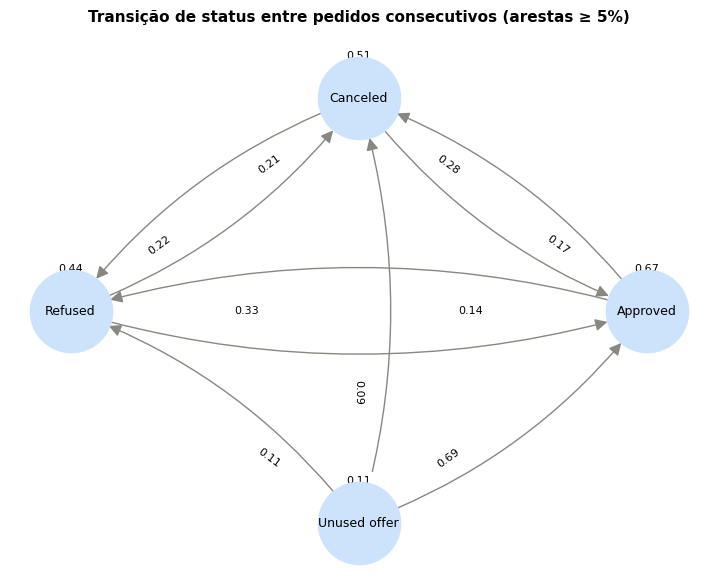

In [16]:
import networkx as nx

sequencia = hist_emprestimos.sort_values(["id_cliente", "data_decisao"]).copy()
sequencia["status_anterior"] = sequencia.groupby("id_cliente")["status_contrato"].shift(1)
transicoes = sequencia.dropna(subset=["status_anterior"])
matriz = pd.crosstab(transicoes["status_anterior"], transicoes["status_contrato"], normalize="index")
display(matriz.round(2))

G = nx.DiGraph()
for origem in matriz.index:
    for destino in matriz.columns:
        if matriz.loc[origem, destino] >= 0.05:
            G.add_edge(origem, destino, weight=matriz.loc[origem, destino])

fig, ax = plt.subplots(figsize=(9, 7))
pos = nx.circular_layout(G)
nx.draw(G, pos, with_labels=True, node_size=3500, node_color="#cde2fb", edge_color=CINZA,
        arrowsize=18, ax=ax, connectionstyle="arc3,rad=0.15", font_size=9)
nx.draw_networkx_edge_labels(
    G, pos, edge_labels={(u, v): f"{d['weight']:.2f}" for u, v, d in G.edges(data=True)},
    label_pos=0.3, font_size=8, ax=ax,
)
ax.set_title("Transição de status entre pedidos consecutivos (arestas ≥ 5%)")
ax.axis("off")
plt.show()

**Leitura.**

- Depois de uma aprovação, o próximo pedido tende a ser aprovado de novo: o cliente que já é bom pagador volta.
- Uma recusa aumenta a chance de outra recusa.
- Cancelamentos se repetem, o que sugere clientes que fazem simulações em sequência.

Isso justifica as features `hist_n_recusados`, `hist_taxa_recusa` e `hist_n_pedidos_90d` (pedidos recentes em excesso podem indicar busca desesperada por crédito).

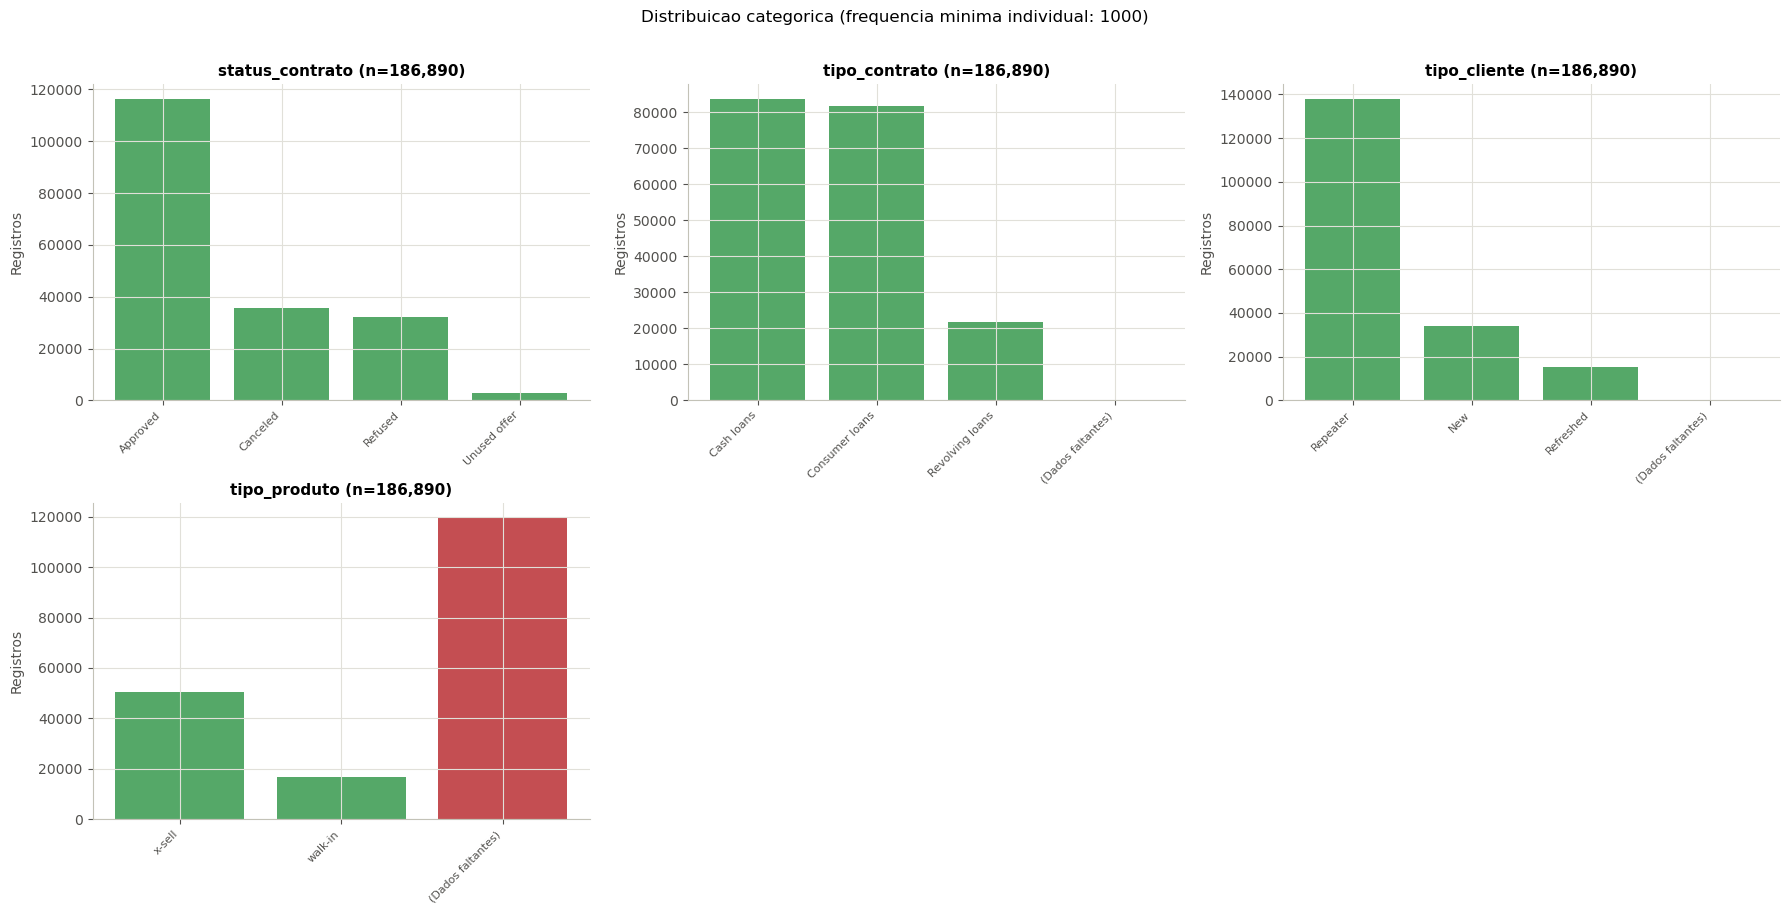

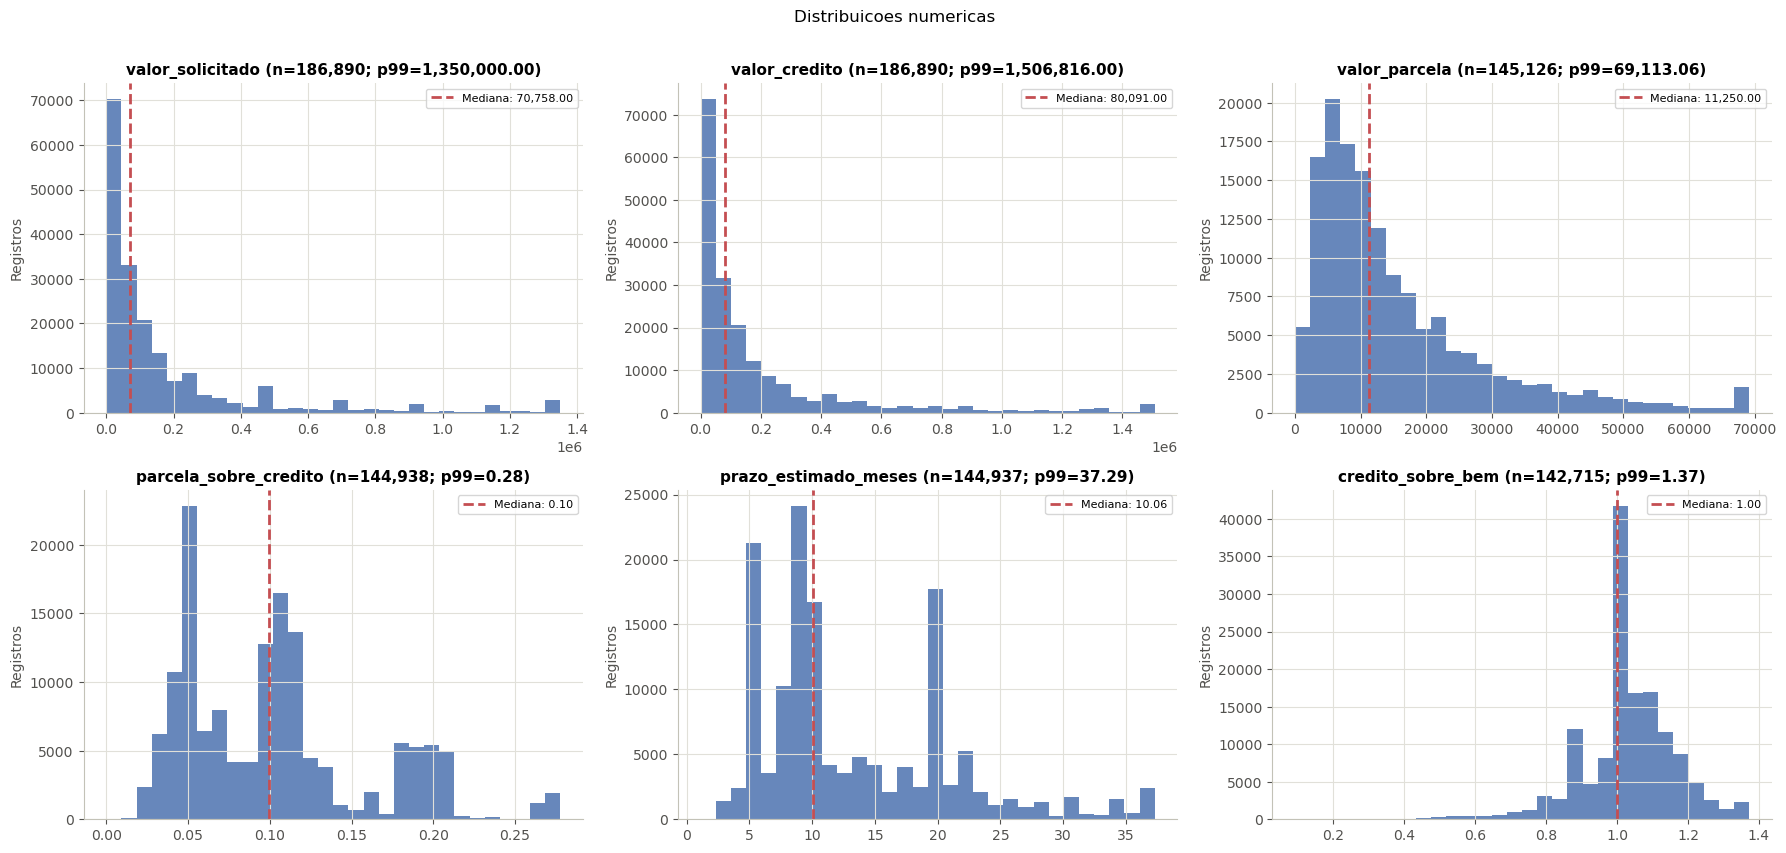

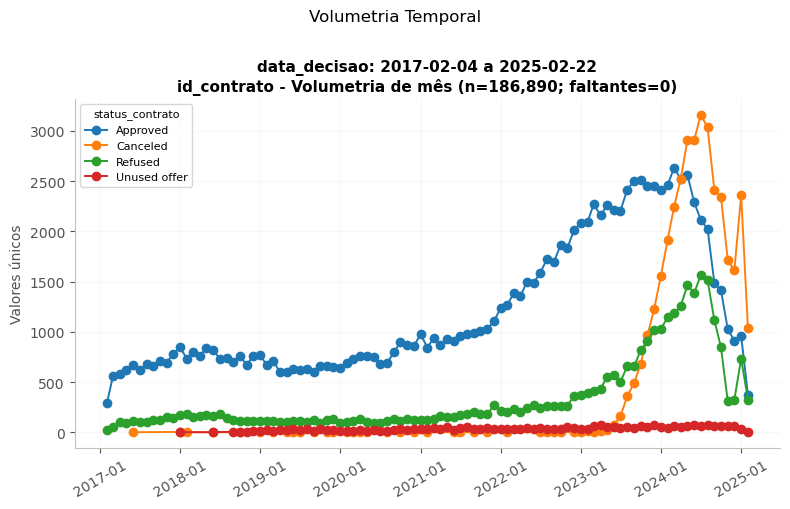

In [17]:
visualizacoes_emprestimos = dataviz(
    dataset=emprestimos_fe,
    feature_cat=["status_contrato", "tipo_contrato", "tipo_cliente", "tipo_produto"],
    feature_num=["valor_solicitado", "valor_credito", "valor_parcela",
                 "parcela_sobre_credito", "prazo_estimado_meses", "credito_sobre_bem"],
    feature_data=["data_decisao"],
    feature_volume="id_contrato",
    feature_data_groupby="status_contrato",
    data_frequency="M",
    volume_aggregation="nunique",
    min_category_count=1000,
)
plt.show()

**Leitura do histórico contratual.**

- 62% dos pedidos foram aprovados.
- O volume mensal de decisões cresce ao longo do tempo. Logo, as safras recentes pesam mais no treino.
- `prazo_estimado_meses` tem picos em ~5, ~10 e ~20 meses. São os prazos contratuais de 6, 12 e 24 meses: como a parcela embute juros, `crédito / parcela` fica um pouco abaixo do prazo real.
- `credito_sobre_bem` fica concentrado em 1 no histórico. Na submissão, fica em ~1,12, mais um sinal de que o produto pedido hoje é diferente.

## 4. Histórico de parcelas

Cada linha é um **pagamento** de uma parcela: uma mesma parcela pode ter várias versões (renegociação ou pagamento parcial). É daqui que sai tanto o comportamento passado (features) quanto o target.

In [18]:
dict_dados[dict_dados["base"] == "historico_parcelas"]

,base,coluna,descricao
61,historico_parcelas,id_contrato,Identificador do contrato de empréstimo
62,historico_parcelas,id_cliente,Identificador do cliente
63,historico_parcelas,versao_parcela,Versão da parcela dentro do contrato (caso haj...
64,historico_parcelas,numero_parcela,Número sequencial da parcela dentro do contrato
65,historico_parcelas,data_prevista_pagamento,Data inicialmente prevista para o pagamento da...
66,historico_parcelas,data_real_pagamento,Data real em que o pagamento foi efetuado
67,historico_parcelas,valor_previsto_parcela,Valor original previsto da parcela
68,historico_parcelas,valor_pago_parcela,Valor efetivamente pago pelo cliente


In [19]:
parcelas_fe = FeatureEngineering.enriquecer_parcelas(hist_parcelas)

print("Dimensões:", hist_parcelas.shape)
print("Linhas exatamente duplicadas:", int(hist_parcelas.duplicated().sum()))
print("Data real ausente (parcela sem pagamento):", int(hist_parcelas["data_real_pagamento"].isna().sum()))
qtd_por_chave = hist_parcelas.groupby(["id_contrato", "numero_parcela", "versao_parcela"]).size()
print("Grupos repetidos por contrato/parcela/versão:", int(qtd_por_chave.gt(1).sum()))
print()
print("Timing dos pagamentos (%):")
display(parcelas_fe["timing_pagamento"].value_counts(normalize=True).mul(100).round(1).to_frame("percentual"))

Dimensões: (1390978, 8)
Linhas exatamente duplicadas: 0
Data real ausente (parcela sem pagamento): 339
Grupos repetidos por contrato/parcela/versão: 68607

Timing dos pagamentos (%):


,percentual
timing_pagamento,
Antecipado,71.9
No vencimento,19.4
Apos vencimento,8.7
Sem pagamento,0.0


### Features criadas nas parcelas

`FeatureEngineering.enriquecer_parcelas` mantém uma linha por pagamento:

| Feature | Cálculo | Por que importa |
|---|---|---|
| `dias_entre_vencimento_e_pagamento` | `data_real − data_prevista` | Negativo indica pagamento antecipado |
| `dias_atraso` (DPD) | o mesmo, com mínimo zero | Medida padrão de atraso: *days past due* |
| `timing_pagamento` | Antecipado / No vencimento / Após vencimento | Resumo categórico do comportamento |
| `valor_pago_sobre_previsto` | `valor_pago / valor_previsto` | < 1 indica pagamento parcial |

Para a base final, as parcelas são consolidadas em **uma linha por contrato/parcela**: vencimento original (o mais antigo) e data de quitação (o pagamento mais recente). Depois são agregadas por cliente, olhando só para parcelas que venceram antes do corte: `hist_dpd_max`, `hist_taxa_atraso`, `hist_n_parcelas_em_aberto`, etc.

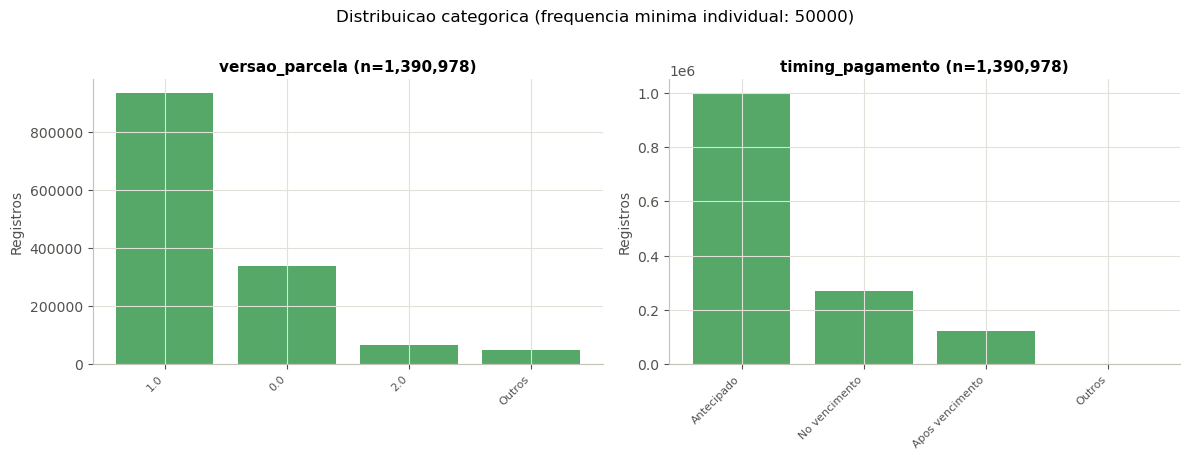

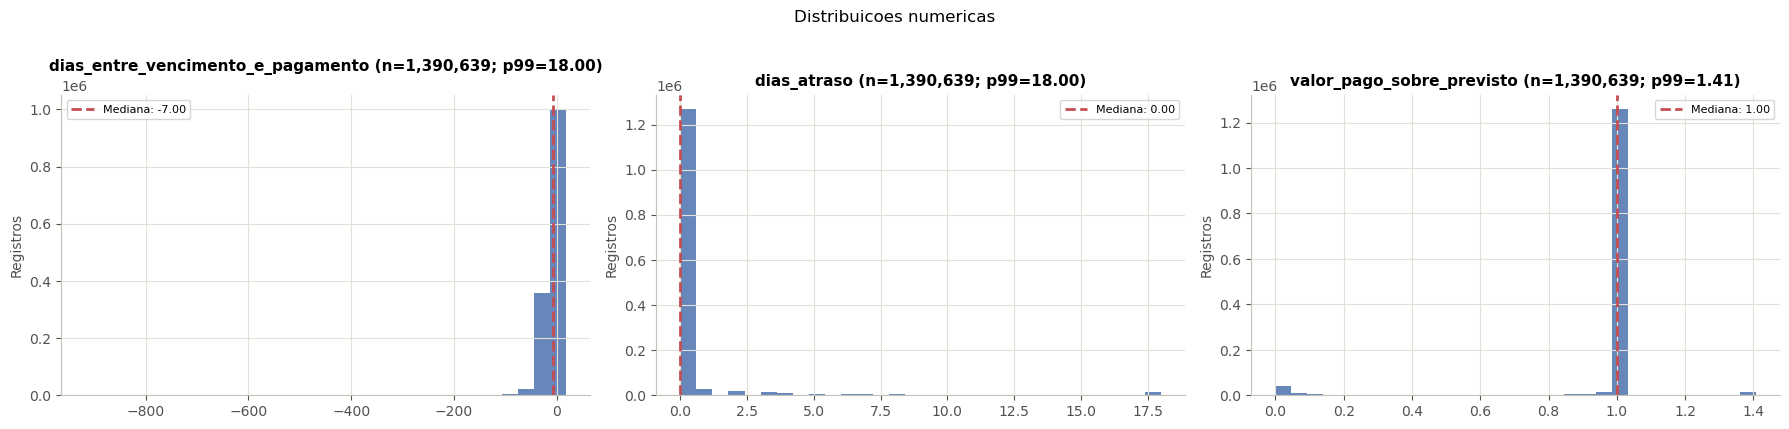

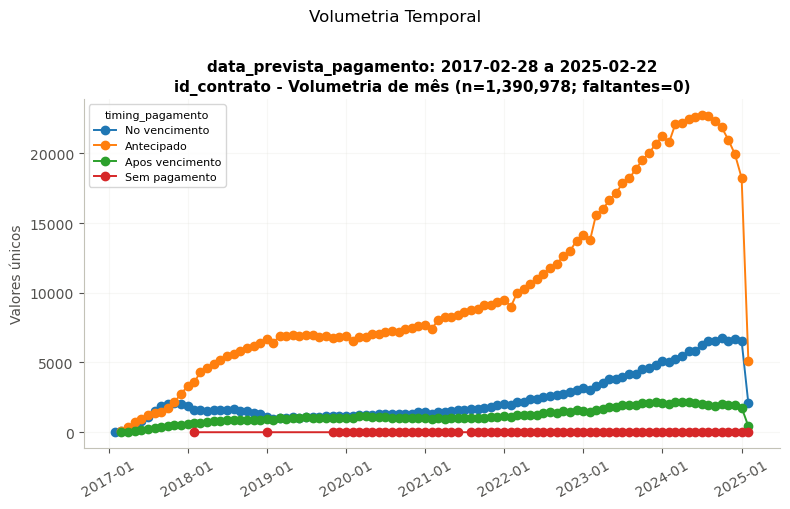

In [20]:
visualizacoes_parcelas = dataviz(
    dataset=parcelas_fe,
    feature_cat=["versao_parcela", "timing_pagamento"],
    feature_num=["dias_entre_vencimento_e_pagamento", "dias_atraso", "valor_pago_sobre_previsto"],
    feature_data=["data_prevista_pagamento"],
    feature_volume="id_contrato",
    feature_data_groupby="timing_pagamento",
    data_frequency="M",
    volume_aggregation="nunique",
    min_category_count=50000,
)
plt.show()

A maioria dos pagamentos é antecipada (~72%) e só ~9% ocorrem após o vencimento. Os histogramas de atraso ficam espremidos perto de zero, então o gráfico abaixo olha apenas os pagamentos atrasados, por faixa de DPD. As faixas seguem a régua regulatória (15/30/60/90 dias).

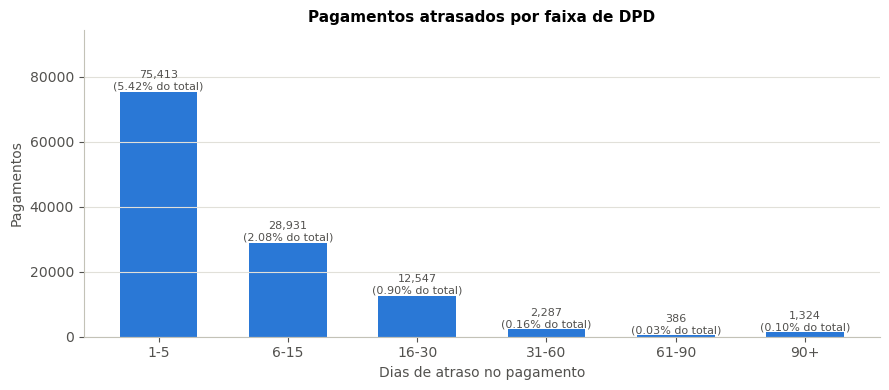

In [21]:
atrasados = parcelas_fe.loc[parcelas_fe["dias_atraso"] > 0, "dias_atraso"]
faixas = pd.cut(atrasados, [0, 5, 15, 30, 60, 90, np.inf],
                labels=["1-5", "6-15", "16-30", "31-60", "61-90", "90+"])
dist = faixas.value_counts(sort=False)
pct = dist / len(parcelas_fe) * 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(dist.index.astype(str), dist.values, color=AZUL, width=0.6)
for i, (n, p) in enumerate(zip(dist.values, pct.values)):
    ax.text(i, n, f"{n:,}\n({p:.2f}% do total)", ha="center", va="bottom", fontsize=8, color="#52514e")
ax.set_xlabel("Dias de atraso no pagamento")
ax.set_ylabel("Pagamentos")
ax.set_title("Pagamentos atrasados por faixa de DPD")
ax.set_ylim(0, dist.max() * 1.25)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Quase todo atraso é curto: a maior parte fica em até 15 dias e é "esquecimento", não incapacidade de pagar. Atrasos de 60+ dias são raros (~0,1% dos pagamentos). Esse é o primeiro sinal de que o target precisa ser escolhido com cuidado: um limiar alto demais gera poucos eventos.

**Por que consolidar versões?** O exemplo abaixo mostra um contrato com várias versões da mesma parcela. Somar as linhas contaria o pagamento duas vezes.

In [22]:
exemplo = hist_parcelas.groupby("id_contrato")["versao_parcela"].nunique().idxmax()
display(
    hist_parcelas[hist_parcelas["id_contrato"] == exemplo]
    .sort_values(["numero_parcela", "versao_parcela"])
    .head(10)
)

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela
1082258,2172856,342987,1.0,1,2022-12-09,2022-12-01,35217.000,49544.055
1082257,2172856,342987,2.0,1,2022-12-09,2022-12-01,14327.055,49544.055
818254,2172856,342987,3.0,2,2023-01-08,2022-12-26,34641.000,45989.100
818255,2172856,342987,4.0,2,2023-01-08,2022-12-26,11348.100,45989.100
890470,2172856,342987,5.0,3,2023-02-07,2023-01-30,34182.000,45989.100
890471,2172856,342987,6.0,3,2023-02-07,2023-01-30,11807.100,45989.100
953748,2172856,342987,7.0,4,2023-03-09,2023-03-03,33687.000,45044.100
953747,2172856,342987,8.0,4,2023-03-09,2023-03-03,11357.100,45044.100
1047313,2172856,342987,9.0,5,2023-04-08,2023-03-29,33210.000,45044.100
1047314,2172856,342987,10.0,5,2023-04-08,2023-03-29,11834.100,45044.100


### Limitação crítica: a tabela só registra parcelas **pagas**

Segundo o PDF do case, cada linha é "uma parcela paga". Só 339 linhas têm pagamento nulo. Ou seja, **um cliente que parou de pagar simplesmente desaparece da tabela**. Se o target olhar apenas as linhas existentes, o pior tipo de inadimplente (quem nunca mais pagou) seria rotulado como bom.

Para não perder esses casos, a classe `TargetEngineering` cria a **próxima parcela esperada, sem pagamento**, quando o contrato:

1. não tem `data_encerramento`, ou seja, ainda está aberto;
2. é parcelado (`qtd_parcelas_planejadas > 0`) e o último número de parcela observado é menor que o planejado;
3. já passou 30 dias do último vencimento observado.

Por que não usar só "parcelas observadas < planejadas"? Porque **47% dos contratos encerrados têm menos parcelas que o planejado**: foram quitados antecipadamente. Por isso, a regra só se aplica a contratos **abertos**.

In [23]:
contratos_aprov = emprestimos_fe[emprestimos_fe["status_contrato"] == "Approved"].set_index("id_contrato")
ultima_parcela = hist_parcelas.groupby("id_contrato")["numero_parcela"].max()
contratos_aprov["parcelas_observadas"] = ultima_parcela

encerrados = contratos_aprov[contratos_aprov["data_encerramento"].notna()]
quitacao_antecipada = (encerrados["parcelas_observadas"] < encerrados["qtd_parcelas_planejadas"]).mean()
print(f"Encerrados com menos parcelas que o planejado (quitação antecipada): {quitacao_antecipada:.1%}")
print(f"Aprovados sem nenhuma parcela registrada: {contratos_aprov['parcelas_observadas'].isna().mean():.1%}")
display(contratos_aprov.groupby("tipo_contrato")["qtd_parcelas_planejadas"].median().to_frame("prazo_planejado_mediano"))

Encerrados com menos parcelas que o planejado (quitação antecipada): 47.1%
Aprovados sem nenhuma parcela registrada: 7.5%


,prazo_planejado_mediano
tipo_contrato,
Cash loans,24.0
Consumer loans,10.0
Revolving loans,0.0


## 5. Definição do target

### 5.1 O que o mercado usa

**Basileia II/III** define *default* como **90 ou mais dias de atraso** (DPD) em uma obrigação relevante, ou a improbabilidade de pagamento. A PD (probabilidade de default) usada no capital regulatório tem **horizonte de 12 meses**. No Brasil, a Res. CMN 2.682/1999 classificava operações de A a H por faixa de atraso: o nível E começa em 91 dias. A Res. CMN 4.966/2021, em vigor desde 2025, adota o mesmo marco de **90 dias** para "ativo problemático".

Em modelos de concessão (*application score*), o target é escrito como:

| Sigla | Significado |
|---|---|
| **MOB** (*months on book*) | Meses desde a contratação |
| **EVERxMOBy** | O contrato atingiu x+ dias de atraso **em algum momento** até o mês y |
| **OVERxMOBy** | O contrato **está** com x+ dias de atraso **no fim** do mês y (foto do status) |
| **FPD** | Atraso na primeira parcela; mede fraude ou erro de cadastro, não capacidade de pagamento |

O alinhamento estrito com Basileia é **EVER90MOB12**. Na prática, bancos e birôs usam com frequência **EVER60MOB12**, ou até EVER30, quando a análise de *roll rate* mostra que esse atraso quase sempre evolui para 90+. Assim o modelo ganha mais eventos sem mudar o que está sendo medido.


### 5.2 Por que existe uma "data de observação"?

Um contrato aprovado em dezembro de 2024 tem só 2 meses de vida nos dados. Ele "não atrasou 60 dias" simplesmente porque **ainda não houve tempo**. Se entrasse como bom (target = 0), o modelo aprenderia que contratos recentes são seguros e as taxas de mau ficariam subestimadas.

A regra, portanto, é: **só rotular contratos cuja janela inteira já passou**, isto é, `data_decisao + 12 meses ≤ data_observacao`. Os demais ficam `NA` e saem do treino.

**A data de observação é por cliente.** O histórico de cada cliente termina na data do pedido dele na base de submissão, e não em uma data única:

- os pedidos da submissão vão de 04/02 a 24/02/2025;
- nenhum cliente tem registro no histórico (pedido ou pagamento) no dia do próprio pedido ou depois. A célula abaixo confere.

Por isso, um contrato só é rotulado quando a janela inteira termina **antes do pedido do cliente**. Usar a última data das bases (22/02/2025) para todos rotularia contratos com até 18 dias da janela sem observar, e trataria como não paga uma parcela que o cliente pode ter pago depois do próprio pedido.

### 5.3 Regras de construção

1. Só contratos **aprovados** recebem target. Recusados nunca tiveram crédito, logo não há comportamento a observar.
2. O MOB conta a partir de `data_decisao`. O primeiro vencimento cai ~30 dias depois (seção 3).
3. Parcelas: vencimento original (o mais antigo entre as versões) e quitação (o pagamento mais recente).
4. Parcelas faltantes de contratos abertos que pararam de pagar entram como não pagas (seção 4).
5. O atraso é medido **até o fim da janela**. Uma parcela que vence no mês 11 e é paga no mês 14 tinha só ~30 dias de atraso no fim do MOB12.

In [24]:
observacao_por_cliente = pd.to_datetime(base_submissao.set_index("id_cliente")["data_solicitacao"])
te = TargetEngineering(hist_emprestimos, hist_parcelas, observacao_por_cliente)

# Conferência: o histórico de cada cliente termina antes do pedido dele na submissão?
ultimo_registro = pd.concat([
    pd.to_datetime(hist_emprestimos["data_decisao"]).groupby(hist_emprestimos["id_cliente"]).max(),
    pd.to_datetime(hist_parcelas["data_real_pagamento"]).groupby(hist_parcelas["id_cliente"]).max(),
], axis=1).max(axis=1)
dias_ate_o_pedido = (observacao_por_cliente - ultimo_registro).dt.days.dropna()
print(f"Clientes com histórico: {len(dias_ate_o_pedido):,} | com registro no dia do próprio pedido ou depois: {int((dias_ate_o_pedido <= 0).sum())}")
print("Data de observação por cliente (data do pedido): de", te.contratos["data_observacao"].min().date(),
      "a", te.contratos["data_observacao"].max().date())
print("Última data presente nas bases:", te.data_observacao.date())
print("Contratos aprovados:", f"{len(te.contratos):,}")
print("Parcelas consolidadas:", f"{len(te.parcelas):,}")
print("Parcelas faltantes criadas (contrato aberto que parou de pagar):",
      f"{int(te.parcelas['data_pagamento'].isna().sum()):,}")

Clientes com histórico: 37,952 | com registro no dia do próprio pedido ou depois: 0
Data de observação por cliente (data do pedido): de 2025-02-04 a 2025-02-24
Última data presente nas bases: 2025-02-22
Contratos aprovados: 116,182
Parcelas consolidadas: 1,313,084
Parcelas faltantes criadas (contrato aberto que parou de pagar): 2,489


### 5.4 Qual limiar de atraso? Análise de *roll rate*

A pergunta é: **dos contratos que atingiram X dias de atraso, quantos chegaram a 90+ (default de Basileia)?** Se quase todos chegam, então atingir X já é, na prática, o default. Usamos só contratos com 24+ meses de vida para que o atraso tenha tempo de evoluir.

,contratos,chegaram_a_90+_%
atingiu_dpd,,
5+,14691,5.8
15+,6498,13.1
30+,2384,35.6
45+,1214,69.9
60+,1023,83.0


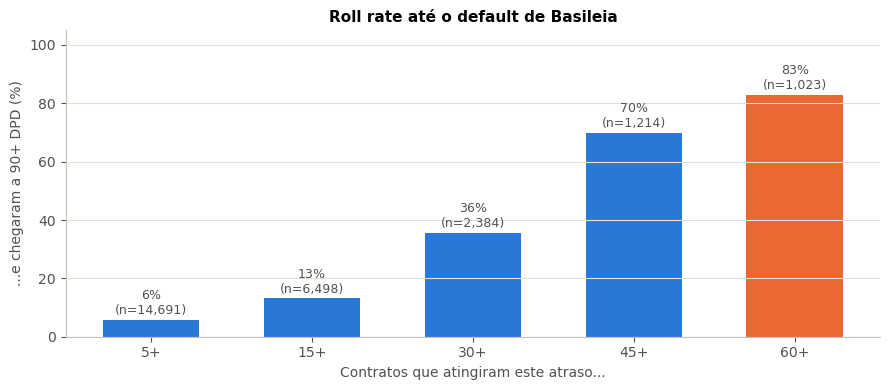

In [25]:
roll = te.roll_rate()
display(roll)

fig, ax = plt.subplots(figsize=(9, 4))
cores = [AZUL if r < 80 else LARANJA for r in roll["chegaram_a_90+_%"]]
ax.bar(roll.index, roll["chegaram_a_90+_%"], color=cores, width=0.6)
for i, (v, n) in enumerate(zip(roll["chegaram_a_90+_%"], roll["contratos"])):
    ax.text(i, v + 2, f"{v:.0f}%\n(n={n:,})", ha="center", fontsize=9, color="#52514e")
ax.set_ylim(0, 105)
ax.set_xlabel("Contratos que atingiram este atraso...")
ax.set_ylabel("...e chegaram a 90+ DPD (%)")
ax.set_title("Roll rate até o default de Basileia")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Leitura.** Atrasos de até 30 dias são majoritariamente "curados": só ~36% dos que chegam a 30+ evoluem para 90+. Já **83% dos que chegam a 60+ terminam em default**. Sessenta dias é o "ponto sem volta" da carteira. Conceitualmente, um target com limiar de 60 dias mede o mesmo evento que o default de Basileia, só que mais cedo.

O limiar de 30 dias é mais "sujo": só um terço de quem chega lá vira default. Em compensação, tem ~3x mais eventos. Qual efeito pesa mais é uma pergunta empírica, respondida na seção 6.4. Lá, o EVER30 vence.

### 5.5 Qual janela? Curva de safra

Para cada janela (MOB 3, 6, 9, 12, 18, 24), calculamos a taxa EVER acumulada, usando só as safras que já completaram 24 meses (assim todos os pontos usam os mesmos contratos). A janela ideal é onde a curva começa a achatar.

,ever30_%,ever60_%,ever90_%
mob,,,
3,0.22,0.00,0.00
6,0.89,0.10,0.02
9,1.89,0.51,0.26
12,2.75,0.92,0.55
18,3.27,1.35,1.10
24,3.46,1.42,1.17


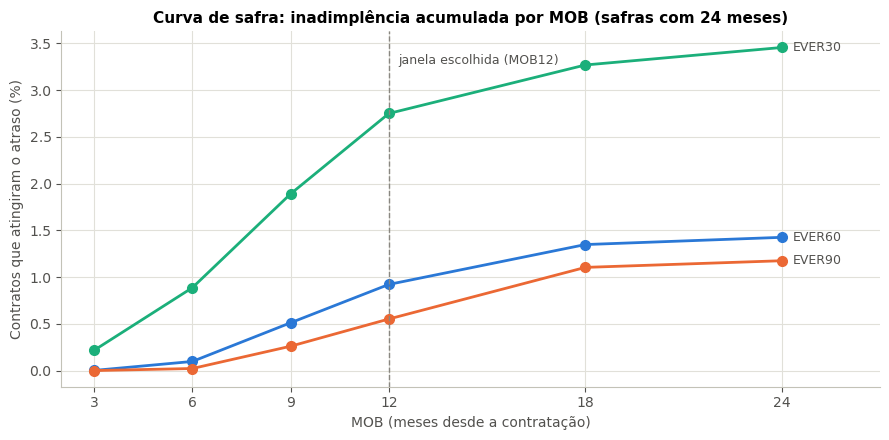

In [26]:
curvas = pd.concat([te.curva_safra(d) for d in (30, 60, 90)], axis=1)
display(curvas.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
for coluna, cor in zip(curvas.columns, [AQUA, AZUL, LARANJA]):
    ax.plot(curvas.index, curvas[coluna], marker="o", markersize=7, linewidth=2, color=cor)
    ax.annotate(coluna.replace("_%", "").upper(), (curvas.index[-1], curvas[coluna].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", color="#52514e", fontsize=9)
ax.axvline(12, color=CINZA, linestyle="--", linewidth=1)
ax.text(12.3, curvas.values.max() * 0.95, "janela escolhida (MOB12)", color="#52514e", fontsize=9)
ax.set_xticks(curvas.index)
ax.set_xlabel("MOB (meses desde a contratação)")
ax.set_ylabel("Contratos que atingiram o atraso (%)")
ax.set_title("Curva de safra: inadimplência acumulada por MOB (safras com 24 meses)")
ax.set_xlim(2, 27)
plt.tight_layout()
plt.show()

**Leitura.**

- Até o MOB6 quase ninguém chega a 60 ou 90 dias. Uma janela de 6 meses capturaria só uma fração pequena dos maus.
- **No MOB12, o EVER30 já captura ~80% do que acontece em 24 meses** (2,75% de 3,46%), e o EVER60 captura ~65%. As curvas achatam depois do MOB18.
- Janelas de 18 ou 24 meses capturariam mais, mas descartariam todas as safras de 2023/2024. O modelo seria treinado com clientes de 2+ anos atrás para pontuar pedidos de 2025.

O MOB12 equilibra três coisas: é o horizonte da PD de Basileia, captura a maior parte dos defaults e preserva safras recentes até fevereiro de 2024.

### 5.6 Comparação das definições

In [27]:
resumo = te.resumo_targets()
display(resumo)

,rotulados,maus,taxa_maus_%,safra_mais_recente
target,,,,
target_ever30mob12,89532,1947,2.17,2024-02-24
target_ever60mob12,89532,665,0.74,2024-02-24
target_ever90mob12,89532,395,0.44,2024-02-24
target_over90mob12,89532,256,0.29,2024-02-24
target_ever30mob06,101731,688,0.68,2024-08-24
target_over60mob06,101731,68,0.07,2024-08-24
target_mau60_bom15_mob12,84877,665,0.78,2024-02-24


,contratos_rotulados,target_ever30mob12,target_ever60mob12,target_ever90mob12
safra,,,,
2017,6693,3.80,1.20,0.78
2018,8911,4.02,1.29,0.70
2019,7594,5.45,1.98,1.20
2020,8905,3.19,0.77,0.40
2021,10958,1.78,0.56,0.36
2022,17870,1.25,0.58,0.39
2023,25434,0.79,0.32,0.18
2024,3167,0.54,0.16,0.00
2025,0,NaN,NaN,NaN


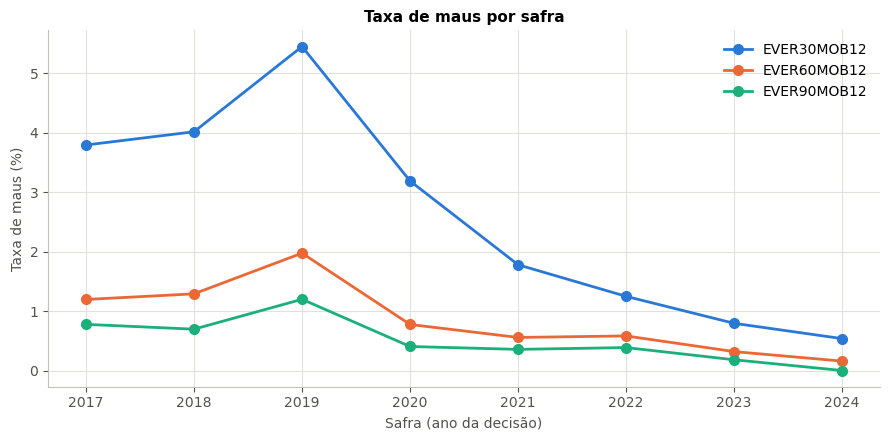

In [28]:
targets = te.construir_targets()
por_safra = targets.merge(te.contratos[["id_contrato", "data_decisao"]], on="id_contrato")
por_safra["safra"] = por_safra["data_decisao"].dt.year
taxa_safra = por_safra.groupby("safra")[[TARGET_PRINCIPAL, "target_ever60mob12", "target_ever90mob12"]].mean().mul(100)
volume_safra = por_safra.groupby("safra")[TARGET_PRINCIPAL].count()
display(pd.concat([volume_safra.rename("contratos_rotulados"), taxa_safra.round(2)], axis=1))

fig, ax = plt.subplots(figsize=(9, 4.5))
for coluna, cor in zip(taxa_safra.columns, [AZUL, LARANJA, AQUA]):
    serie = taxa_safra[coluna].dropna()
    ax.plot(serie.index, serie.values, marker="o", markersize=7, linewidth=2, color=cor,
            label=coluna.replace("target_", "").upper())
ax.set_xlabel("Safra (ano da decisão)")
ax.set_ylabel("Taxa de maus (%)")
ax.set_title("Taxa de maus por safra")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Leitura.** A taxa de maus cai muito nas safras recentes, em todas as definições. No EVER30MOB12, sai de 3,8–5,5% (2017–2019) para ~0,8% (2023). Parte disso pode ser melhora real da política de crédito. Outra parte é consistente com o viés de sobrevivência discutido na seção 5.7: quem atrasou um contrato recente tem menos chance de estar pedindo crédito novo agora e, portanto, de estar na base. Por isso:

- a validação deve ser **temporal** (treinar em safras antigas e testar nas mais recentes), não um split aleatório;
- a PD final deve ser **calibrada** na taxa das safras mais recentes.

### 5.7 Por que a taxa de maus é tão baixa?

Entre 0,4% (EVER90MOB12) e 2,2% (EVER30MOB12) de maus é pouco para crédito pessoal. Antes de aceitar o número, testamos se ele vem de um erro na construção do target. Cada linha da tabela abaixo é uma forma de um mau pagador "escapar" do target:

1. **Calote disfarçado de quitação.** Um contrato baixado como perda pode ter `data_encerramento` e parcelas a menos, exatamente como uma quitação antecipada, e a regra de parcela faltante só olha contratos abertos. Se for quitação de verdade, o último pagamento deve ser grande e o total pago deve cobrir o crédito.
2. **Pagamento parcial.** A regra considera a parcela paga na data do último pagamento, mesmo que o valor tenha sido só uma fração.
3. **Aprovados sem nenhuma parcela.** Ficam fora do treino (target NA). Podem ser créditos nunca usados ou clientes que não pagaram nem a primeira parcela.
4. **Quem está na amostra.** Se o histórico só contém clientes que voltaram a pedir crédito, quem deu calote e sumiu não aparece.

In [29]:
pagamentos = hist_parcelas.dropna(subset=["data_real_pagamento"]).drop_duplicates(
    ["id_contrato", "numero_parcela", "data_real_pagamento", "valor_pago_parcela"]
)  # o mesmo pagamento se repete entre versões da parcela
contratos_aprov["total_pago"] = pagamentos.groupby("id_contrato")["valor_pago_parcela"].sum()
contratos_aprov["ultimo_pagamento"] = (
    pagamentos.sort_values("data_real_pagamento").groupby("id_contrato")["valor_pago_parcela"].last()
)

encerrados_cedo = contratos_aprov[
    contratos_aprov["data_encerramento"].notna()
    & (contratos_aprov["parcelas_observadas"] < contratos_aprov["qtd_parcelas_planejadas"])
]
quitacao_em_lote = encerrados_cedo["ultimo_pagamento"] >= 1.5 * encerrados_cedo["valor_parcela"]
pagou_menos_que_credito = encerrados_cedo["total_pago"] < encerrados_cedo["valor_credito"]

previsto = hist_parcelas.groupby(["id_contrato", "numero_parcela"])["valor_previsto_parcela"].max()
pago = pagamentos.groupby(["id_contrato", "numero_parcela"])["valor_pago_parcela"].sum()
pago_sobre_previsto = (pago / previsto).dropna()

sem_parcela = contratos_aprov[contratos_aprov["parcelas_observadas"].isna()]
clientes_fora_submissao = set(hist_emprestimos["id_cliente"]) - set(base_submissao["id_cliente"])

testes = pd.DataFrame([
    ("1. Encerrados antes do prazo", f"{len(encerrados_cedo):,} contratos",
     f"{quitacao_em_lote.mean():.0%} terminam com pagamento ≥ 1,5 parcela; "
     f"{pagou_menos_que_credito.mean():.1%} pagaram menos que o crédito"),
    ("2. Pagamento parcial", f"{len(pago_sobre_previsto):,} parcelas",
     f"{(pago_sobre_previsto < 0.9).mean():.2%} receberam menos de 90% do previsto"),
    ("3. Aprovados sem parcela", f"{len(sem_parcela):,} contratos",
     f"{sem_parcela['data_primeiro_vencimento'].notna().mean():.0%} têm 1º vencimento definido; "
     f"{sem_parcela['tipo_contrato'].eq('Revolving loans').mean():.0%} são Revolving"),
    ("4. Amostra", f"{hist_emprestimos['id_cliente'].nunique():,} clientes no histórico",
     f"{len(clientes_fora_submissao)} clientes do histórico fora da submissão"),
], columns=["teste", "volume", "resultado"]).set_index("teste")
display(testes)

,volume,resultado
teste,,
1. Encerrados antes do prazo,"40,580 contratos","97% terminam com pagamento ≥ 1,5 parcela; 0.0%..."
2. Pagamento parcial,"1,310,595 parcelas",0.02% receberam menos de 90% do previsto
3. Aprovados sem parcela,"8,763 contratos",0% têm 1º vencimento definido; 44% são Revolving
4. Amostra,"37,952 clientes no histórico",0 clientes do histórico fora da submissão


**Leitura dos testes.**

1. **Não é calote disfarçado.** Quase todo contrato encerrado antes do prazo termina com um pagamento de várias parcelas de uma vez, e nenhum pagou menos que o crédito. São quitações antecipadas de verdade.
2. **Não é pagamento parcial.** Praticamente toda parcela registrada foi paga integralmente.
3. **Não são caloteiros escondidos.** Nenhum dos aprovados sem parcela tem data de primeiro vencimento: são créditos aprovados e nunca utilizados (principalmente limites de Revolving que o cliente não sacou). É correto deixá-los fora do treino.
4. **A amostra é condicionada.** Todos os clientes do histórico estão pedindo crédito em fevereiro de 2025. A base é o passado de quem *voltou*. Quem deu calote grave e foi para cobrança, foi negativado ou simplesmente sumiu não está aqui.

Então a taxa baixa não é bug: vem de **quem está na amostra**. Além disso, nesta carteira o atraso é frequente, mas quase sempre curto, como mostra a distribuição abaixo (vida inteira do contrato, não só os 12 primeiros meses):

,% dos contratos (vida toda)
1+ dias,32.40
5+ dias,18.09
15+ dias,7.18
30+ dias,2.61
60+ dias,1.07
90+ dias,0.85


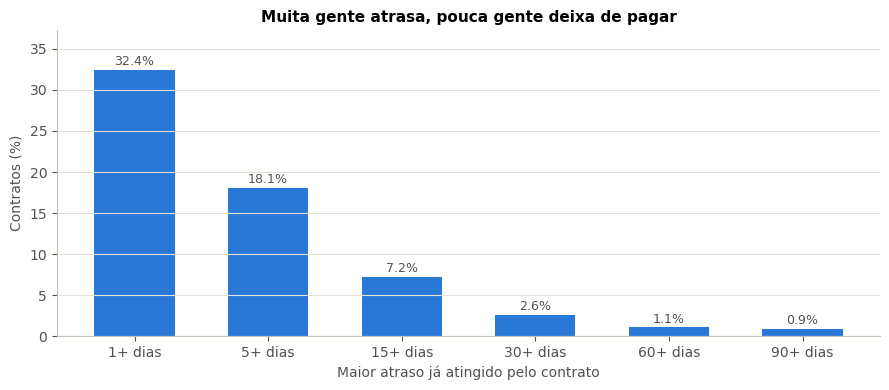

In [30]:
vida = te.parcelas.merge(te.contratos[["id_contrato", "data_observacao"]], on="id_contrato")
dpd_vida = (vida["data_pagamento"].fillna(vida["data_observacao"]) - vida["data_vencimento"]).dt.days.clip(lower=0)
dpd_max_vida = dpd_vida.groupby(vida["id_contrato"]).max()

limiares = [1, 5, 15, 30, 60, 90]
pct_vida = pd.Series({f"{d}+ dias": (dpd_max_vida >= d).mean() * 100 for d in limiares})
display(pct_vida.round(2).to_frame("% dos contratos (vida toda)"))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(pct_vida.index, pct_vida.values, color=AZUL, width=0.6)
for i, v in enumerate(pct_vida.values):
    ax.text(i, v + 0.6, f"{v:.1f}%", ha="center", fontsize=9, color="#52514e")
ax.set_ylabel("Contratos (%)")
ax.set_xlabel("Maior atraso já atingido pelo contrato")
ax.set_title("Muita gente atrasa, pouca gente deixa de pagar")
ax.set_ylim(0, pct_vida.max() * 1.15)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Leitura.** Um terço dos contratos já atrasou pelo menos um dia, e ~7% chegaram a 15 dias. Mas menos de 1% chegou a 90 dias. Uma expectativa de 5–8% de maus corresponde, nesta carteira, a "atrasou 15 dias", não a default.

Resumindo, a taxa baixa tem quatro causas:

1. **Sobrevivência:** só clientes que voltaram a pedir crédito.
2. **Seleção:** só contratos aprovados pela política atual (17% dos pedidos foram recusados).
3. **Perfil do atraso:** curto e quase sempre curado.
4. **Janela:** o MOB12 captura cerca de metade dos 90+ que aparecem em 24 meses.

A estrutura (tipos Cash/Consumer/Revolving, códigos `XNA`/`XAP`, juros 99,7% nulos, liberação quase sempre vazia) também lembra o dataset público *Home Credit Default Risk*, em que o histórico é justamente "pedidos anteriores de quem está pedindo agora". Isso é uma dedução, não algo confirmado.

**O que isso significa para o modelo:**

- O viés pesa menos do que parece, porque a população pontuada tem a mesma seleção: clientes que voltaram, 95% com histórico.
- A **ordenação** de risco deve funcionar, mas o **nível** da PD provavelmente subestima o risco de um cliente novo. Vale considerar isso na política de crédito.
- Com tão poucos eventos, vale testar um limiar menor. A seção 5.9 compara os candidatos, e a seção 6.4 testa qual deles treina o melhor modelo.

### 5.8 Quem vira linha de treino e quem será pontuado

**Treino: só contratos aprovados.** O target precisa de um desfecho de pagamento, e só quem recebeu o crédito tem parcelas. Recusados, cancelados e ofertas não usadas não viram linhas de treino. Eles continuam sendo usados como **informação** nos pedidos seguintes do cliente (`hist_n_recusados`, `hist_taxa_recusa`, `hist_n_cancelados`, `hist_n_pedidos_90d`).

**O problema (*reject inference*).** A submissão é formada por **pedidos**, pontuados antes da decisão. Ela inclui perfis que a política atual recusaria, e o modelo nunca viu como esses perfis pagam. Dá para medir o tamanho do problema de forma indireta: parte dos clientes recusados conseguiu um contrato aprovado logo depois, e sabemos como esse contrato se saiu.

In [31]:
alvo_comparacao = te.construir_target(30, 12)
alvo_comparacao = alvo_comparacao[alvo_comparacao["target_ever30mob12"].notna()]
pedidos = hist_emprestimos[["id_contrato", "id_cliente", "data_decisao", "status_contrato"]].assign(
    data_decisao=lambda d: pd.to_datetime(d["data_decisao"])
)


def proximo_aprovado(pedidos_status, meses=6):
    """Primeiro contrato aprovado e rotulado do cliente nos `meses` seguintes ao pedido."""
    m = pedidos_status.merge(alvo_comparacao, on="id_cliente", suffixes=("", "_seguinte"))
    janela = (m["data_decisao_seguinte"] > m["data_decisao"]) & (
        m["data_decisao_seguinte"] <= m["data_decisao"] + pd.DateOffset(months=meses)
    )
    return m[janela].sort_values("data_decisao_seguinte").drop_duplicates("id_contrato")


linhas = []
for status in ["Refused", "Approved", "Canceled", "Unused offer"]:
    origem = pedidos[pedidos["status_contrato"] == status]
    seguinte = proximo_aprovado(origem)
    linhas.append({
        "status_do_pedido": status,
        "pedidos": len(origem),
        "com_aprovado_em_6m_%": round(len(seguinte) / len(origem) * 100, 1),
        "taxa_EVER30MOB12_do_seguinte_%": round(seguinte["target_ever30mob12"].mean() * 100, 2),
    })
display(pd.DataFrame(linhas).set_index("status_do_pedido"))

,pedidos,com_aprovado_em_6m_%,taxa_EVER30MOB12_do_seguinte_%
status_do_pedido,,,
Refused,32108,14.6,1.94
Approved,116182,13.4,1.24
Canceled,35767,2.8,0.69
Unused offer,2833,18.7,0.94


**Leitura.**

- O contrato aprovado logo depois de uma **recusa** tem taxa de maus de ~1,94%, contra ~1,24% depois de uma **aprovação**: os recusados são ~1,6x mais arriscados. A política atual filtra bem, e é justamente nesse grupo que o modelo tem menos informação.
- Esse número cobre só os 15% de recusados que voltaram e foram aprovados, provavelmente os "menos ruins" do grupo. O risco real dos recusados deve ser maior.
- Cancelados e ofertas não usadas não mostram risco maior. Faz sentido: foi o cliente que desistiu, não o banco que recusou.

**O que fazer.** Não vamos transformar recusados em "maus" automaticamente, porque isso confundiria a regra da política atual com inadimplência real. O caminho proposto:

1. **Na política:** não aprovar automaticamente faixas de score onde se concentram perfis parecidos com os recusados do histórico; essas faixas vão para análise manual.
2. **Na modelagem (opcional):** testar técnicas de *reject inference*, como reponderar os aprovados parecidos com recusados (*augmentation*). São técnicas padrão, mas trazem premissas difíceis de validar.
3. **Em produção:** monitorar a distribuição de score dos pedidos contra a do treino.

**E quem será pontuado?** A pergunta complementar é se os clientes da submissão se parecem com a população de treino. Classificamos cada um pelo que aconteceu **antes** da data da solicitação:

In [32]:
historico_antes = base_submissao[["id_cliente", "data_solicitacao"]].merge(
    pedidos.assign(tem_parcela=pedidos["id_contrato"].isin(hist_parcelas["id_contrato"])),
    on="id_cliente", how="left",
)
print("Pedidos do histórico no dia ou depois da solicitação:",
      int((historico_antes["data_decisao"] >= pd.to_datetime(historico_antes["data_solicitacao"])).sum()))
historico_antes = historico_antes[historico_antes["data_decisao"] < pd.to_datetime(historico_antes["data_solicitacao"])]

por_cliente = historico_antes.groupby("id_cliente").agg(
    pedidos=("id_contrato", "size"),
    aprovados=("status_contrato", lambda s: (s == "Approved").sum()),
    aprovados_usados=("tem_parcela", "sum"),
).reindex(base_submissao["id_cliente"]).fillna(0)

perfil = pd.Series("Sem nenhum pedido anterior", index=por_cliente.index)
perfil[por_cliente["pedidos"] > 0] = "Só pedidos não aprovados"
perfil[por_cliente["aprovados"] > 0] = "Aprovado, mas nunca usou o crédito"
perfil[por_cliente["aprovados_usados"] > 0] = "Aprovado e com histórico de pagamento"
display(perfil.value_counts().to_frame("clientes").assign(pct=lambda d: (d["clientes"] / len(perfil) * 100).round(1)))

Pedidos do histórico no dia ou depois da solicitação: 0


,clientes,pct
Aprovado e com histórico de pagamento,37739,94.3
Sem nenhum pedido anterior,2048,5.1
Só pedidos não aprovados,122,0.3
"Aprovado, mas nunca usou o crédito",91,0.2


**Leitura.**

- **94% dos clientes da submissão já tiveram um crédito aprovado e usado**, com histórico de pagamento observável. Para eles, as features de comportamento (as mais fortes, segundo o IV) estão disponíveis, e o modelo pontua o mesmo tipo de cliente com que treinou.
- **~5% não têm nenhum pedido anterior.** São clientes novos, para quem o modelo só conta com cadastro e dados do pedido. No treino, esse grupo tem o dobro da taxa de maus de quem tem histórico (3,2% contra 1,5%, seção 6.2), então a política deve tratá-lo de forma específica, por exemplo com limite inicial menor.
- **~0,5%** só tiveram pedidos recusados/cancelados ou aprovações nunca usadas.
- Nenhum pedido do histórico é do mesmo dia ou posterior à solicitação: as features da submissão não vazam informação do futuro.

Isso reforça o ponto da seção 5.7: a carteira é de clientes recorrentes. O viés de sobrevivência afeta treino e submissão da mesma forma, então a **ordenação** do modelo é válida para quem será pontuado. Já o **nível** da PD não deve ser extrapolado para clientes novos.

### 5.9 Decisão

| Definição | Maus | Papel |
|---|---|---|
| **EVER30MOB12** | ~1.950 | **Target principal.** Horizonte de 12 meses (PD de Basileia), com 3x mais eventos que o EVER60. Ordenou melhor até o default de Basileia em safras futuras (seção 6.4) |
| EVER60MOB12 | ~670 | Limiar no ponto sem volta (83% roll para 90+). Conceitualmente mais limpo, mas com menos eventos ordenou pior |
| MAU60_BOM15_MOB12 | ~670 | Formato clássico de *scorecard*: mau 60+, bom até 15 dias, indeterminados (16–59 dias, ~4.700 contratos) fora do treino. Melhor que o EVER60, mas ainda abaixo do EVER30 |
| EVER90MOB12 | ~400 | **Benchmark regulatório.** O modelo deve ordenar bem este evento, e a política reporta sua taxa por faixa de score |
| OVER90MOB12 | ~260 | Default ainda vigente no fim do ano (o que de fato gera perda) |
| EVER30MOB06 | ~700 | Alerta precoce; usa safras até agosto de 2024. Bom para monitoramento |
| OVER60MOB06 | ~70 | Sugestão do case: poucos eventos nesta carteira, então não serve para treino |

**FPD** foi descartado como target principal: o FPD30 ocorre em menos de 0,1% dos contratos. Além disso, o primeiro pagamento mede mais fraude do que risco de crédito.

**Como a escolha segue a prática de mercado.** Bancos definem o target de concessão em quatro passos, e cada um foi feito aqui:

1. **Roll rate** para escolher o limiar de dias (seção 5.4). O limiar "de livro" seria 60 dias.
2. **Curva de safra** para escolher a janela (seção 5.5). Doze meses é também o horizonte da PD de Basileia.
3. **Volume de eventos.** A literatura de *scorecards* costuma citar ~1.500–2.000 maus como confortável. Nenhuma definição com 60 ou 90 dias passa de ~670 nesta carteira; o EVER30MOB12 tem ~1.950.
4. **Validação empírica** (seção 6.4). O mesmo modelo foi treinado com cada candidato, inclusive no formato com indeterminados, e o EVER30MOB12 ordenou melhor o default de Basileia em safras futuras.

O EVER30MOB12 se afasta da regra do roll rate (só ~36% de quem chega a 30 dias vira default). Essa escolha é consciente: com poucos eventos, o ganho de volume pesou mais que a "pureza" do target. O evento regulatório (EVER90MOB12) continua sendo a régua de avaliação e de perda.

**O que a probabilidade entregue significa.** A `probabilidade_inadimplencia` da submissão será a probabilidade de o contrato **atingir 30 ou mais dias de atraso nos primeiros 12 meses**. Como só ~36% desses casos viram default de Basileia, a política de crédito usa o score para **ordenar** os pedidos e mede a perda esperada com a taxa observada de EVER90MOB12 em cada faixa.

**Limitações assumidas.**

- A taxa de maus é baixa (2,2% no EVER30MOB12): será preciso tratar o desbalanceamento, com pesos de classe e métricas AUC/KS em vez de acurácia.
- O target mistura atrasos que se curam com defaults. É o preço de ter eventos suficientes para treinar.
- O treino só tem aprovados, enquanto os recusados são ~1,6x mais arriscados (seção 5.8). O modelo enxerga menos justamente o perfil de maior risco.
- A amostra só tem clientes que voltaram a pedir crédito (seção 5.7).
- Revolving loans não têm cronograma, então a regra de parcela faltante não se aplica a eles.
- A ausência de `data_liberacao` faz o MOB começar na decisão.

## 6. Base final de modelagem

`FeatureEngineering.construir_base(pedidos, coluna_data_corte)` gera **uma linha por pedido**, com:

1. **Colunas do pedido** que existem igualmente na submissão: `tipo_contrato`, `valor_credito`, `valor_bem`, `valor_parcela`, dia e hora da solicitação, mais as razões da seção 2.
2. **Cadastro** com as features da seção 1, mais `idade`, `parcela_sobre_renda` e `credito_sobre_renda`, calculadas **na data do pedido**.
3. **Histórico point-in-time:** agregados de tudo que aconteceu com o cliente **antes** da data de corte.

| Grupo | Features | Intuição |
|---|---|---|
| Pedidos anteriores | `hist_n_pedidos`, `hist_n_aprovados`, `hist_n_recusados`, `hist_n_cancelados`, `hist_taxa_recusa` | Recusas passadas indicam que outros analistas já viram risco |
| Intensidade recente | `hist_n_pedidos_90d`, `hist_n_pedidos_365d`, `hist_dias_desde_ultimo_pedido` | Muitos pedidos em pouco tempo indicam busca por crédito |
| Tamanho | `hist_valor_aprovado_medio` | Experiência com valores parecidos ao pedido atual |
| Pagamentos | `hist_n_parcelas`, `hist_n_contratos_com_parcela`, `hist_n_parcelas_365d` | Quanto histórico de pagamento existe |
| Atraso | `hist_n_parcelas_atraso`, `_atraso_30`, `_atraso_60`, `hist_dpd_max`, `hist_dpd_medio`, `hist_taxa_atraso`, `hist_taxa_atraso_365d` | Frequência e severidade dos atrasos passados |
| Recência | `hist_dias_desde_ultimo_atraso` | Um atraso de 5 anos atrás pesa menos que um do mês passado |
| **Situação no dia** | `hist_n_parcelas_em_aberto`, `hist_dpd_atual` | O cliente **está** inadimplente em outro contrato no momento do pedido? |
| Sem histórico | `hist_sem_historico` | Cliente novo: as médias acima ficam nulas e esta flag diferencia o caso |

**Contagens sem histórico são 0; médias, máximos e recências ficam `NaN`.** Um cliente sem parcelas não tem "atraso médio zero": a métrica simplesmente não existe para ele.

| Base | Linhas | Data de corte | Target |
|---|---|---|---|
| Treino | Contratos aprovados e maduros do histórico | `data_decisao` | Sim |
| Score | `base_submissao` | `data_solicitacao` | Não (é o que vamos prever) |

Colunas pós-decisão do histórico (liberação, vencimentos, encerramento, motivo de recusa) **não entram**. A base de treino tem exatamente as mesmas features da base de score.

In [33]:
fe = FeatureEngineering(hist_emprestimos, hist_parcelas, base_cadastral)

pedidos_treino = hist_emprestimos.merge(targets, on="id_contrato")      # só aprovados
base_treino_completa = fe.construir_base(pedidos_treino, "data_decisao")
base_modelagem = base_treino_completa[base_treino_completa[TARGET_PRINCIPAL].notna()].reset_index(drop=True)
base_score = fe.construir_base(base_submissao, "data_solicitacao")

COLUNAS_ID = ["id_cliente", "id_contrato", "data_referencia"]
TARGETS = [c for c in base_modelagem.columns if c.startswith("target_")]
FEATURES = [c for c in base_score.columns if c not in COLUNAS_ID]
FEATURES_CATEGORICAS = [c for c in FEATURES if base_score[c].dtype == object]
FEATURES_NUMERICAS = [c for c in FEATURES if c not in FEATURES_CATEGORICAS]

assert set(FEATURES) <= set(base_modelagem.columns), "treino e score com features diferentes"
assert base_modelagem["id_contrato"].is_unique and base_score["id_cliente"].is_unique

print(f"Base de modelagem: {base_modelagem.shape[0]:,} contratos | taxa de maus {base_modelagem[TARGET_PRINCIPAL].mean():.2%}")
print(f"Base de score:     {base_score.shape[0]:,} pedidos")
print(f"Features: {len(FEATURES)} ({len(FEATURES_NUMERICAS)} numéricas, {len(FEATURES_CATEGORICAS)} categóricas)")
print("Categóricas:", FEATURES_CATEGORICAS)
base_modelagem.head()

Base de modelagem: 89,532 contratos | taxa de maus 2.17%
Base de score:     40,000 pedidos
Features: 51 (40 numéricas, 11 categóricas)
Categóricas: ['tipo_contrato', 'dia_semana_solicitacao', 'sexo', 'tipo_renda', 'ocupacao', 'tipo_organizacao', 'nivel_educacao', 'estado_civil', 'tipo_moradia', 'possui_carro', 'possui_imovel']


,id_contrato,id_cliente,target_ever30mob12,target_ever60mob12,target_ever90mob12,target_over90mob12,target_ever30mob06,target_over60mob06,target_mau60_bom15_mob12,tipo_contrato,valor_credito,valor_bem,valor_parcela,dia_semana_solicitacao,hora_solicitacao,data_referencia,parcela_sobre_credito,prazo_estimado_meses,credito_sobre_bem,renda_per_capita,sexo,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade,idade,parcela_sobre_renda,credito_sobre_renda,hist_n_pedidos,hist_n_aprovados,hist_n_recusados,hist_n_cancelados,hist_n_pedidos_90d,hist_n_pedidos_365d,hist_valor_aprovado_medio,hist_dias_desde_ultimo_pedido,hist_taxa_recusa,hist_n_parcelas,hist_n_contratos_com_parcela,hist_n_parcelas_atraso,hist_n_parcelas_atraso_30,hist_n_parcelas_atraso_60,hist_dpd_max,hist_dpd_medio,hist_n_parcelas_365d,hist_n_parcelas_atraso_365d,hist_dias_desde_ultimo_atraso,hist_n_parcelas_em_aberto,hist_dpd_atual,hist_taxa_atraso,hist_taxa_atraso_365d,hist_sem_historico
0,2330894,258628,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Cash loans,174361.5,148500.0,12165.210,TUESDAY,15,2022-10-11,0.069770,14.332798,1.174152,56250.0,F,0,2.0,112500.0,Commercial associate,Laborers,Self-employed,Secondary / secondary special,Married,House / apartment,N,Y,3,3,52.0,0.108135,1.549880,3,3,0,0,0,2,80800.50,252.0,0.0,18,3,0,0,0,0.0,0.000000,12,0,NaN,0,0.0,0.000000,0.0,0
1,1182516,267782,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Cash loans,451777.5,405000.0,20361.600,SATURDAY,4,2023-04-08,0.045070,22.187721,1.115500,202500.0,F,0,1.0,202500.0,Pensioner,None,NaN,Secondary / secondary special,Separated,House / apartment,N,Y,2,2,61.0,0.100551,2.231000,4,3,0,0,0,0,18273.00,705.0,0.0,14,2,0,0,0,0.0,0.000000,0,0,NaN,0,0.0,0.000000,NaN,0
2,1543131,275707,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Cash loans,241920.0,229500.0,22619.520,THURSDAY,8,2024-02-08,0.093500,10.695187,1.054118,189000.0,F,0,1.0,189000.0,Working,None,Self-employed,Secondary / secondary special,Single / not married,Municipal apartment,N,Y,2,2,48.0,0.119680,1.280000,1,1,0,0,0,0,71325.00,610.0,0.0,12,1,0,0,0,0.0,0.000000,4,0,NaN,0,0.0,0.000000,0.0,0
3,2741581,383645,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Cash loans,450000.0,450000.0,47407.500,SUNDAY,13,2023-08-06,0.105350,9.492169,1.000000,135000.0,M,0,2.0,270000.0,Commercial associate,Laborers,Transport: type 4,Secondary / secondary special,Married,House / apartment,Y,N,1,1,36.0,0.175583,1.666667,4,4,0,0,0,0,198798.75,384.0,0.0,44,4,1,0,0,1.0,0.022727,11,0,1330.0,0,0.0,0.022727,0.0,0
4,1009986,360684,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Consumer loans,60642.0,57600.0,11451.735,TUESDAY,14,2023-03-28,0.188842,5.295442,1.052812,189000.0,F,0,1.0,189000.0,Working,Laborers,Business Entity Type 3,Higher education,Separated,House / apartment,N,Y,2,2,50.0,0.060591,0.320857,0,0,0,0,0,0,NaN,NaN,NaN,0,0,0,0,0,NaN,NaN,0,0,NaN,0,NaN,NaN,NaN,1


**Verificação do corte temporal.** Para um contrato qualquer, recontamos à mão os pedidos anteriores do cliente e comparamos com `hist_n_pedidos`. Pedidos do mesmo dia ou posteriores não podem entrar.

In [34]:
linha = base_modelagem[base_modelagem["hist_n_pedidos"] >= 3].iloc[0]
pedidos_cliente = hist_emprestimos[hist_emprestimos["id_cliente"] == linha["id_cliente"]].copy()
pedidos_cliente["data_decisao"] = pd.to_datetime(pedidos_cliente["data_decisao"])
esperado = int((pedidos_cliente["data_decisao"] < linha["data_referencia"]).sum())

print(f"Contrato {linha['id_contrato']} decidido em {linha['data_referencia'].date()}")
print(f"Pedidos anteriores recontados: {esperado} | feature hist_n_pedidos: {linha['hist_n_pedidos']}")
assert esperado == linha["hist_n_pedidos"]
display(pedidos_cliente.sort_values("data_decisao")[["id_contrato", "data_decisao", "status_contrato", "tipo_contrato"]])

Contrato 2330894 decidido em 2022-10-11
Pedidos anteriores recontados: 3 | feature hist_n_pedidos: 3


,id_contrato,data_decisao,status_contrato,tipo_contrato
155495,1487892,2019-02-21,Approved,Consumer loans
121329,2513298,2021-10-13,Approved,Cash loans
14549,1104154,2022-02-01,Approved,Cash loans
1,2330894,2022-10-11,Approved,Cash loans
79954,2422921,2023-08-29,Refused,Cash loans
150438,1197401,2023-08-31,Canceled,Cash loans
37961,1321768,2023-12-02,Canceled,Revolving loans
160670,1347266,2024-08-01,Canceled,Revolving loans


### 6.1 Distribuição das features históricas

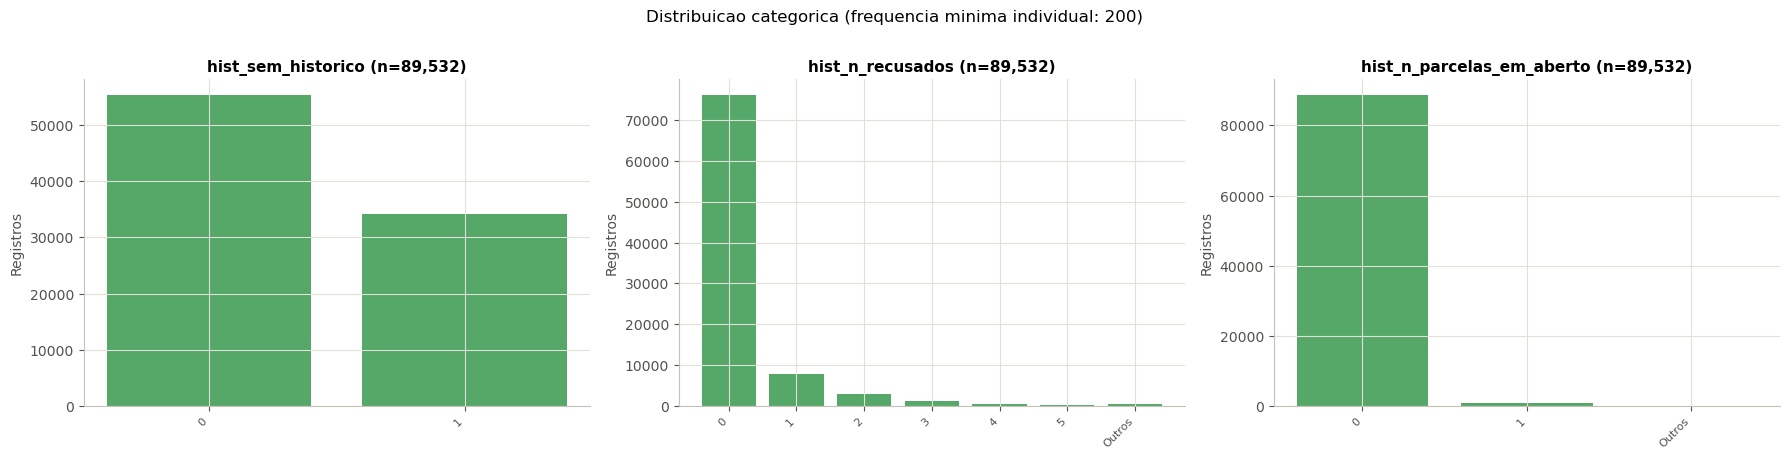

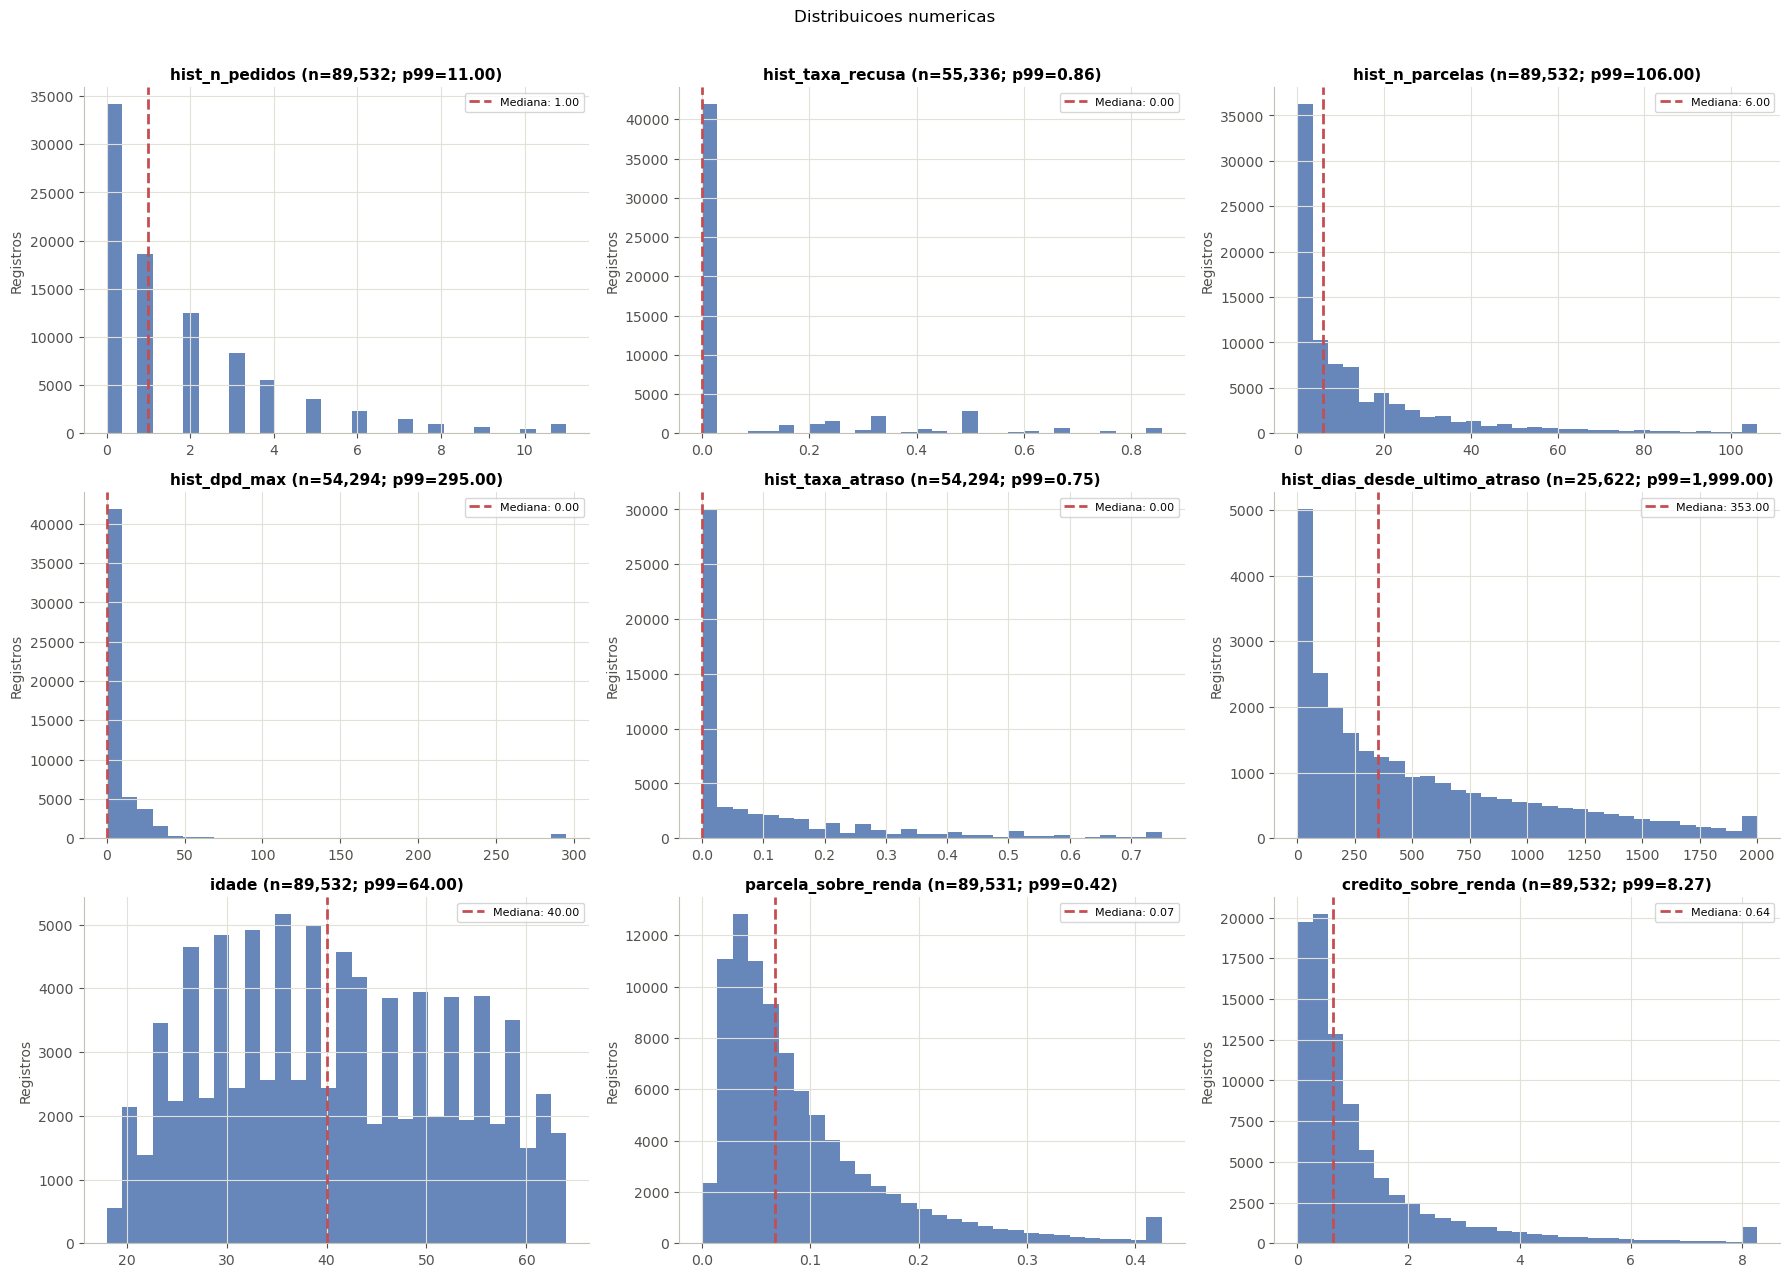

In [35]:
visualizacoes_historico = dataviz(
    dataset=base_modelagem,
    feature_cat=["hist_sem_historico", "hist_n_recusados", "hist_n_parcelas_em_aberto"],
    feature_num=["hist_n_pedidos", "hist_taxa_recusa", "hist_n_parcelas",
                 "hist_dpd_max", "hist_taxa_atraso", "hist_dias_desde_ultimo_atraso",
                 "idade", "parcela_sobre_renda", "credito_sobre_renda"],
    min_category_count=200,
)
plt.show()

**Leitura.**

- `hist_sem_historico`: ~38% dos contratos de treino não têm pedido anterior. Os dados começam em 2017, então as primeiras safras quase não têm passado. Na submissão, esse número é só ~5%. Mais uma diferença de população a monitorar.
- `hist_dpd_max` tem mediana baixa e cauda longa: a maioria dos clientes já atrasou alguns dias em algum momento. O que diferencia é o atraso **grande** ou **recente**.
- `hist_n_parcelas_em_aberto` é quase sempre 0. Quando não é, o cliente está devendo em outro contrato no dia do pedido.

### 6.2 Poder de separação: taxa de maus por faixa

Para cada feature, os contratos são divididos em faixas (quintis ou categorias) e a taxa de maus de cada faixa é comparada à média da carteira (linha tracejada). Uma feature útil tem faixas bem acima e bem abaixo da média.

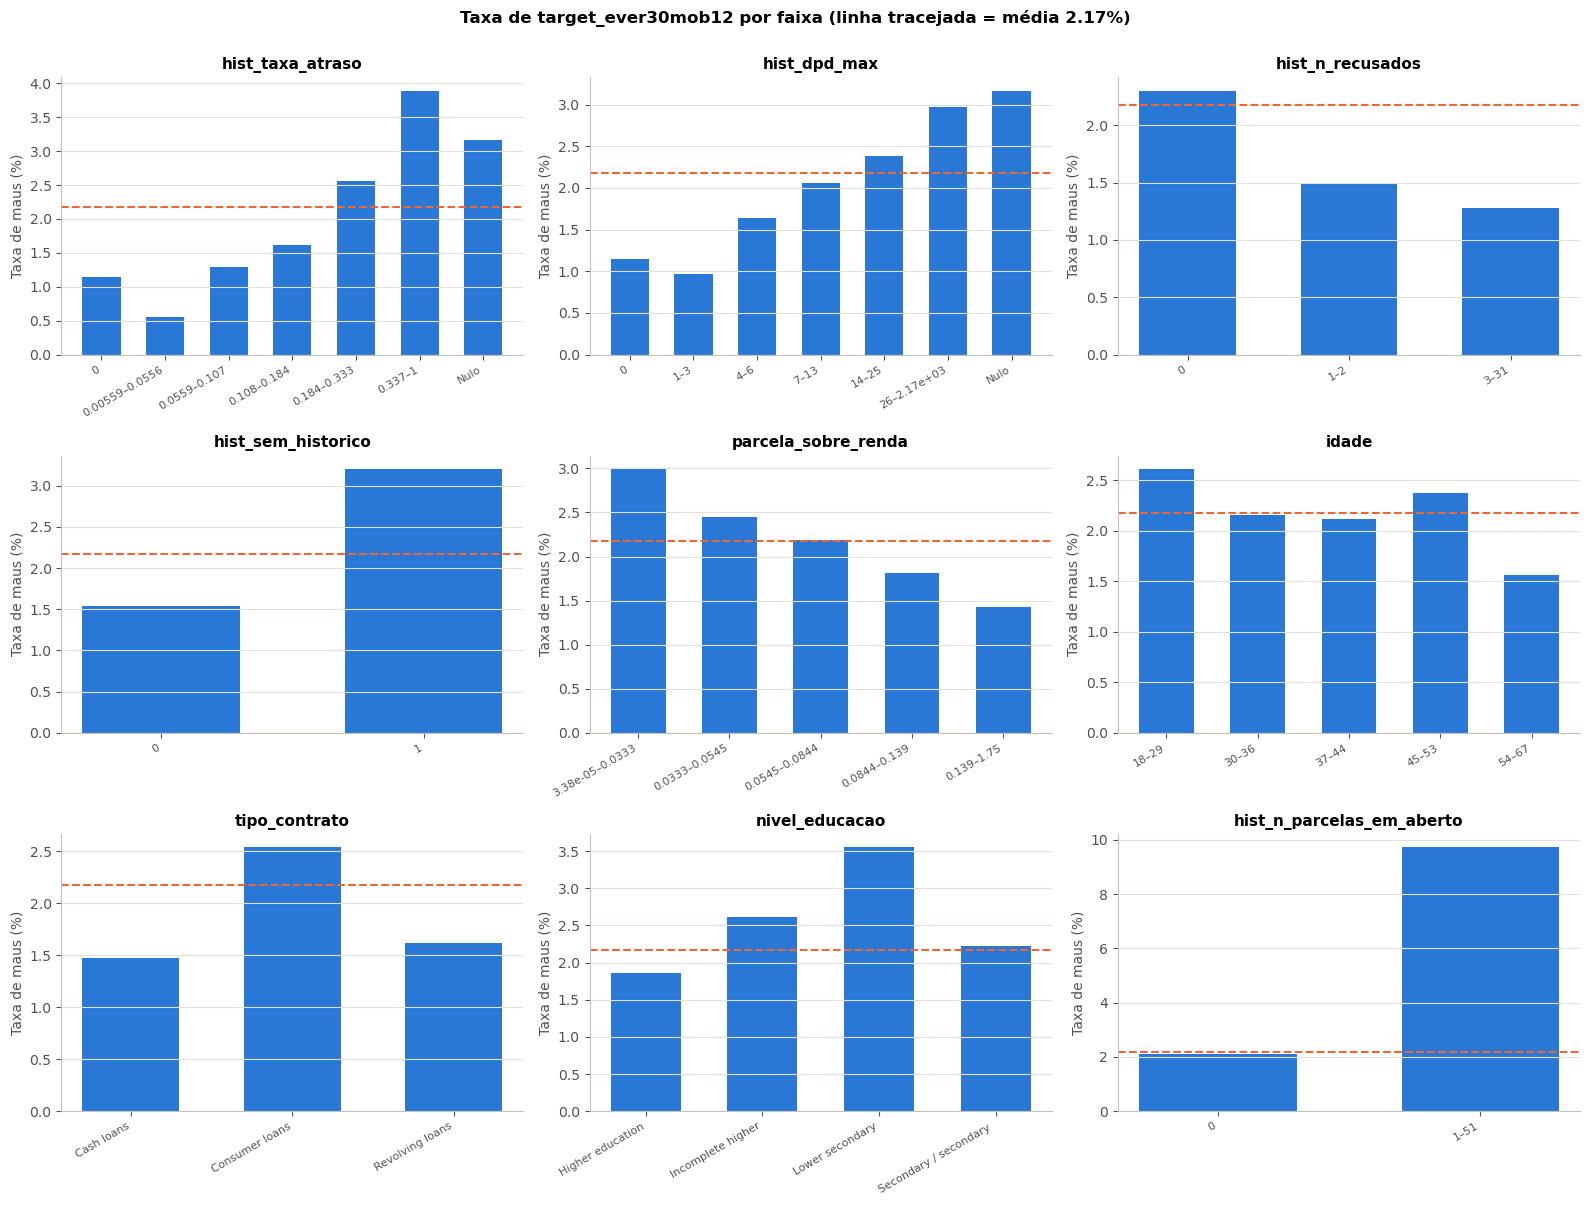

In [36]:
def faixas(x, n=5):
    """Agrupa uma feature para análise univariada.

    Categóricas (ou numéricas com poucos valores) ficam como estão. Nas numéricas,
    nulo e zero viram faixas próprias e os demais valores são divididos em quantis;
    cada faixa é rotulada pelo mínimo e máximo reais que contém.
    """
    if not pd.api.types.is_numeric_dtype(x) or x.nunique() <= n:
        return x.astype(str).where(x.notna(), "Nulo")
    codigo = pd.Series(-1.0, index=x.index).where(x.notna())
    nao_zero = x.notna() & x.ne(0)
    codigo[nao_zero] = pd.qcut(x[nao_zero], n, labels=False, duplicates="drop")
    limites = x.groupby(codigo).agg(["min", "max"])
    nomes = {c: f"{a:.3g}" if a == b else f"{a:.3g}–{b:.3g}" for c, (a, b) in limites.iterrows()}
    return codigo.map(nomes).fillna("Nulo")


def taxa_por_faixa(df, feature, target=TARGET_PRINCIPAL, n=5):
    grupos = faixas(df[feature], n)
    tabela = df.groupby(grupos)[target].agg(["mean", "size"])
    if pd.api.types.is_numeric_dtype(df[feature]):
        ordem = df[feature].groupby(grupos).min().reindex(tabela.index).sort_values(na_position="last")
        tabela = tabela.loc[ordem.index]
    return tabela[tabela["size"] >= 200]

features_plot = [
    "hist_taxa_atraso", "hist_dpd_max", "hist_n_recusados", "hist_sem_historico",
    "parcela_sobre_renda", "idade", "tipo_contrato", "nivel_educacao", "hist_n_parcelas_em_aberto",
]
taxa_media = base_modelagem[TARGET_PRINCIPAL].mean() * 100

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, feature in zip(axes.flat, features_plot):
    tabela = taxa_por_faixa(base_modelagem, feature)
    ax.bar(range(len(tabela)), tabela["mean"] * 100, color=AZUL, width=0.6)
    ax.axhline(taxa_media, color=LARANJA, linestyle="--", linewidth=1.5)
    ax.set_xticks(range(len(tabela)), [str(i)[:22] for i in tabela.index], rotation=30, ha="right", fontsize=8)
    ax.set_title(feature)
    ax.set_ylabel("Taxa de maus (%)")
    ax.grid(axis="x", visible=False)
fig.suptitle(f"Taxa de {TARGET_PRINCIPAL} por faixa (linha tracejada = média {taxa_media:.2f}%)", y=1.0, fontweight="bold")
plt.tight_layout()
plt.show()

**Leitura.**

- **Histórico de pagamento é o sinal mais claro.** A taxa de maus sobe quase monotonicamente com `hist_taxa_atraso` (de ~0,6% para ~3,9%) e com `hist_dpd_max` (de ~1% para ~2,9%).
- Quem **está** com parcela em aberto em outro contrato no dia do pedido (`hist_n_parcelas_em_aberto ≥ 1`) tem taxa de ~9,7%, mais de 4x a média.
- **Sem histórico é risco:** 3,2% contra 1,5%. A faixa "Nulo" das features de atraso é exatamente esse grupo.
- **Dois padrões contraintuitivos, e por que não são o que parecem:**
  - *Parcela/renda maior com menos maus* é efeito do **mix de produto** (paradoxo de Simpson). Consumer loans têm parcela pequena em relação à renda e taxa de maus maior, por isso dominam as primeiras faixas. Dentro de Cash loans, a relação é praticamente plana (~1,5%, ~1,8% e ~1,4% por tercil): o comprometimento de renda, isoladamente, quase não separa risco. Ele **não** protege, como o gráfico agregado sugere.
  - *Zero recusas com mais maus*: 45% desses contratos são de clientes **sem histórico nenhum**. Entre quem tem histórico, a diferença praticamente some.

Essa é a razão para não escolher features por gráficos univariados: o modelo multivariado, com `tipo_contrato` e `hist_sem_historico`, separa esses efeitos.

**Information Value (IV).** É a métrica padrão em crédito para resumir o poder de separação de uma feature num número só. Referência usual: < 0,02 é inútil; 0,02–0,1 é fraca; 0,1–0,3 é média; > 0,3 é forte. Aqui, a feature é dividida com a mesma função `faixas` (nulo e zero como faixas próprias, decis no restante).

,IV,forca
prazo_estimado_meses,0.294,média
hist_taxa_atraso,0.290,média
parcela_sobre_credito,0.281,média
hist_dpd_medio,0.275,média
hist_dpd_atual,0.233,média
hist_taxa_atraso_365d,0.220,média
hist_dpd_max,0.220,média
valor_bem,0.219,média
valor_credito,0.211,média
hist_valor_aprovado_medio,0.205,média


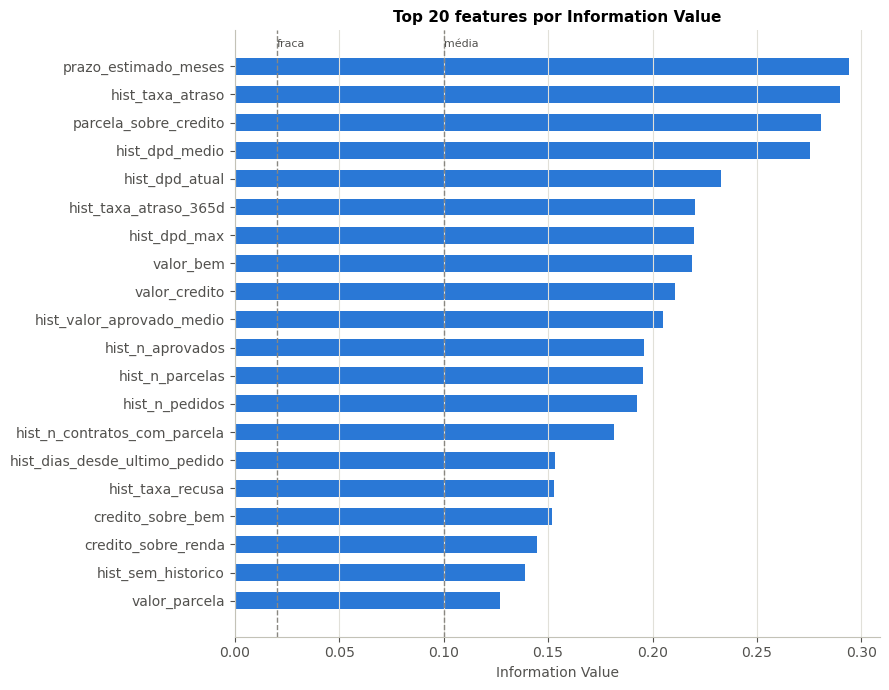

In [37]:
def information_value(df, feature, target=TARGET_PRINCIPAL, n=10):
    tabela = pd.crosstab(faixas(df[feature], n), df[target].astype(int))
    maus = (tabela[1] + 0.5) / tabela[1].sum()      # +0,5 evita log(0) em faixas sem maus
    bons = (tabela[0] + 0.5) / tabela[0].sum()
    return float(((bons - maus) * np.log(bons / maus)).sum())

iv = pd.Series({f: information_value(base_modelagem, f) for f in FEATURES}).sort_values(ascending=False)
iv_tabela = iv.to_frame("IV").assign(
    forca=pd.cut(iv, [-np.inf, 0.02, 0.1, 0.3, np.inf], labels=["inútil", "fraca", "média", "forte"])
)
display(iv_tabela.round(3))

top = iv.head(20).sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top.values, color=AZUL, height=0.6)
for limite, rotulo in [(0.02, "fraca"), (0.1, "média")]:
    ax.axvline(limite, color=CINZA, linestyle="--", linewidth=1)
    ax.text(limite, len(top) - 0.3, rotulo, color="#52514e", fontsize=8, ha="left")
ax.set_xlabel("Information Value")
ax.set_title("Top 20 features por Information Value")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**O IV alto das razões do pedido vem do produto?** `prazo_estimado_meses` e `parcela_sobre_credito` diferem muito entre Cash, Consumer e Revolving. Se o IV delas cair muito quando olhamos só `Cash loans` (o produto da submissão), parte do poder delas é apenas "qual é o produto".

In [38]:
cash = base_modelagem[base_modelagem["tipo_contrato"] == "Cash loans"]
print(f"Cash loans: {len(cash):,} contratos, {int(cash[TARGET_PRINCIPAL].sum())} maus")
top_iv = iv.head(12).index
iv_por_produto = pd.DataFrame({
    "IV_todos": iv[top_iv],
    "IV_cash_loans": [information_value(cash, f) for f in top_iv],
})
display(iv_por_produto.round(3))

Cash loans: 26,444 contratos, 390 maus


,IV_todos,IV_cash_loans
prazo_estimado_meses,0.294,0.250
hist_taxa_atraso,0.290,0.479
parcela_sobre_credito,0.281,0.237
hist_dpd_medio,0.275,0.446
hist_dpd_atual,0.233,0.230
hist_taxa_atraso_365d,0.220,0.360
hist_dpd_max,0.220,0.259
valor_bem,0.219,0.187
valor_credito,0.211,0.197
hist_valor_aprovado_medio,0.205,0.230


**Leitura do IV.**

- **Nenhuma feature isolada é "forte"** (IV > 0,3). As melhores ficam entre 0,2 e 0,3: o sinal está distribuído em muitas features, o que é comum quando o evento é raro.
- **Parte do IV das razões vem do produto, mas só uma parte.** Dentro de `Cash loans`, o IV de `prazo_estimado_meses` cai de 0,29 para 0,25 e o de `parcela_sobre_credito` cai de 0,28 para 0,24. As razões continuam úteis dentro do produto.
- **O comportamento de pagamento fica mais forte dentro do produto:** `hist_taxa_atraso` vai de 0,29 para 0,48, e `hist_dpd_medio` de ~0,28 para ~0,45. Para quem pede Cash loan, o histórico de pagamento point-in-time é o melhor preditor.
- O IV em Cash loans usa 390 maus. É razoável para comparar ordens de grandeza, mas não deve ser lido como valor exato.
- Features com IV < 0,02 (sexo, filhos, carro, imóvel, nota da região, dia/hora do pedido, tipo de renda, escolaridade, estado civil) quase não separam bons de maus. São candidatas a sair do modelo. Sexo também deveria sair por equidade, independentemente do IV.

### 6.3 Estabilidade: treino vs. submissão (PSI)

O *Population Stability Index* compara a distribuição de cada feature no treino com a da submissão. Referência: < 0,1 é estável; 0,1–0,25 merece atenção; > 0,25 indica mudança relevante. Features com PSI alto exigem cuidado, porque o modelo vai vê-las em faixas que pouco viu no treino.

In [39]:
def psi(treino, score, faixas=10):
    if pd.api.types.is_numeric_dtype(treino) and treino.nunique() > faixas:
        cortes = np.unique(np.nanquantile(treino, np.linspace(0, 1, faixas + 1)))
        cortes[0], cortes[-1] = -np.inf, np.inf
        treino, score = pd.cut(treino, cortes), pd.cut(score, cortes)
    esperado = treino.astype(str).value_counts(normalize=True)
    atual = score.astype(str).value_counts(normalize=True)
    esperado, atual = esperado.align(atual, fill_value=0)
    esperado, atual = esperado + 1e-4, atual + 1e-4
    return float(((atual - esperado) * np.log(atual / esperado)).sum())

psi_tabela = pd.Series(
    {f: psi(base_modelagem[f], base_score[f]) for f in FEATURES}
).sort_values(ascending=False).to_frame("PSI")
psi_tabela["situacao"] = pd.cut(psi_tabela["PSI"], [-np.inf, 0.1, 0.25, np.inf],
                                labels=["estável", "atenção", "mudou"])
display(psi_tabela.join(iv.rename("IV")).round(3))
print(psi_tabela["situacao"].value_counts())

cash_score = base_score[base_score["tipo_contrato"] == "Cash loans"]
psi_cash = pd.Series({f: psi(cash[f], cash_score[f]) for f in FEATURES})
print(f"\nFeatures com PSI > 0,25: todos os produtos {int((psi_tabela['PSI'] > 0.25).sum())} "
      f"| só Cash loans {int((psi_cash > 0.25).sum())}")
comparacao_psi = pd.DataFrame({"PSI_todos": psi_tabela["PSI"], "PSI_cash_loans": psi_cash})
display(comparacao_psi.sort_values("PSI_cash_loans", ascending=False).round(3).head(12))

,PSI,situacao,IV
tipo_contrato,6.414,mudou,0.060
valor_credito,3.278,mudou,0.211
valor_bem,3.223,mudou,0.219
prazo_estimado_meses,3.184,mudou,0.294
credito_sobre_renda,3.162,mudou,0.145
parcela_sobre_credito,3.126,mudou,0.281
credito_sobre_bem,2.430,mudou,0.152
valor_parcela,1.790,mudou,0.127
parcela_sobre_renda,1.736,mudou,0.072
hist_n_cancelados,1.538,mudou,0.016


situacao
estável    23
mudou      23
atenção     5
Name: count, dtype: int64

Features com PSI > 0,25: todos os produtos 23 | só Cash loans 8


,PSI_todos,PSI_cash_loans
hist_n_cancelados,1.538,1.324
prazo_estimado_meses,3.184,0.815
parcela_sobre_credito,3.126,0.799
credito_sobre_renda,3.162,0.740
valor_bem,3.223,0.631
valor_credito,3.278,0.603
credito_sobre_bem,2.430,0.433
parcela_sobre_renda,1.736,0.297
valor_parcela,1.790,0.246
hist_n_pedidos,0.766,0.222


**Leitura.**

- **Carteira toda:** 23 das 51 features mudaram (PSI > 0,25). Isso inclui tudo que descreve o pedido (valores, prazo, crédito/renda, parcela/renda) e as features históricas.
- **Só Cash loans contra Cash loans:** sobram 8. As features históricas passam a ficar estáveis ou em atenção leve (PSI ≤ 0,22), então a mudança delas vinha da diferença de mix de produto, não do comportamento dos clientes.
- O que continua mudando dentro de Cash loans é **o próprio pedido**: os pedidos de 2025 são maiores e mais longos (valores, prazo, parcela/crédito, crédito/renda, crédito/bem). Também muda `hist_n_cancelados`, que tem IV ~0 e pode sair.
- **O cadastro é estável** em todos os recortes.

Implicações para a modelagem:

1. Treinar com todos os produtos e `tipo_contrato` como feature (Cash loans sozinho tem só 390 maus), mas **medir a performance em Cash loans**.
2. As features históricas são a base mais confiável: são as mais fortes dentro do produto e estáveis.
3. Features do pedido entram com cautela: o modelo vai vê-las em faixas mais altas do que viu no treino. Vale limitar (*cap*) nos percentis do treino e monitorar.
4. Acompanhar o PSI em produção.

### 6.4 Qual target treina o melhor modelo?

Contar eventos não basta. A pergunta certa é: **treinando o mesmo modelo com cada target, qual deles ordena melhor os clientes que de fato deram default?**

Os candidatos:

| Target | Mau | Bom | Fora do treino |
|---|---|---|---|
| EVER30MOB12 | 30+ dias | o resto | — |
| EVER60MOB12 | 60+ dias | o resto | — |
| **MAU60_BOM15_MOB12** | 60+ dias | nunca passou de 15 dias | 16 a 59 dias (**indeterminados**) |
| EVER90MOB12 | 90+ dias | o resto | — |

O terceiro é o formato clássico de *scorecards* de mercado. Os clientes "no meio do caminho" (atrasaram, mas não chegaram ao mau) não ensinam claramente nem o que é bom nem o que é mau, então ficam fora do treino. Eles **continuam sendo pontuados** em produção e entram normalmente na avaliação.

O experimento:

- **Modelo:** um mesmo `HistGradientBoostingClassifier`, simples e com regularização, que aceita nulos e categóricas sem pré-processamento. Ele não é o modelo final, só a régua de comparação.
- **Divisão temporal:** treino nas safras antigas, teste nas mais recentes. Dois cortes (julho de 2021 e janeiro de 2022) para ver se o resultado se repete.
- **Treino:** uma vez com cada target, usando só as linhas rotuladas daquele target.
- **Avaliação:** AUC de cada modelo medida no **default de Basileia (EVER90MOB12)** em **todo** o teste, na carteira toda e só em Cash loans.
- **Incerteza:** intervalo de confiança de 95% da diferença de AUC entre o EVER30 e cada concorrente, por bootstrap (o teste tem só ~100–150 defaults).

AUC = 0,5 é um modelo aleatório; quanto mais perto de 1, melhor a ordenação.

Corte 2021-07-01: 37,313 treino / 52,219 teste (144 defaults EVER90 no teste)
   IC95% da diferença de AUC (EVER30 − MAU60_BOM15_MOB12): [+0.007, +0.093]
   IC95% da diferença de AUC (EVER30 − EVER60MOB12): [+0.022, +0.115]
Corte 2022-01-01: 43,061 treino / 46,471 teste (115 defaults EVER90 no teste)
   IC95% da diferença de AUC (EVER30 − MAU60_BOM15_MOB12): [-0.020, +0.073]
   IC95% da diferença de AUC (EVER30 − EVER60MOB12): [-0.028, +0.073]


linhas_treino  maus_no_treino  AUC_ever90_todos  AUC_ever90_cash
corte      treinado_com                                                                       
2021-07-01 EVER30MOB12                37313            1386             0.621            0.693
           MAU60_BOM15_MOB12          33848             431             0.571            0.625
           EVER60MOB12                37313             431             0.551            0.580
           EVER90MOB12                37313             251             0.500            0.513
2022-01-01 EVER30MOB12                43061            1505             0.665            0.741
           MAU60_BOM15_MOB12          39319             475             0.638            0.723
           EVER60MOB12                43061             475             0.641            0.715
           EVER90MOB12                43061             280             0.587            0.655

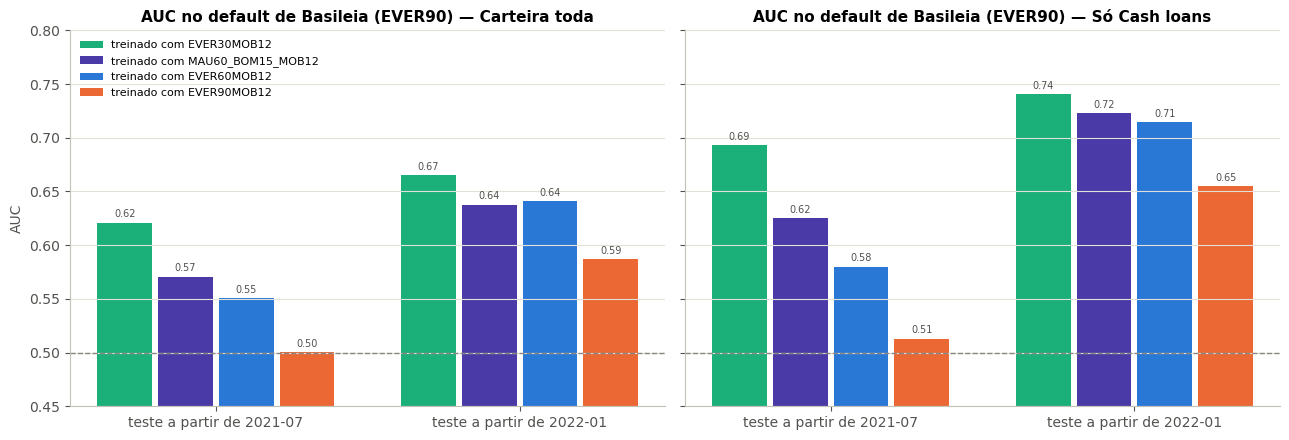

In [40]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # evita aviso do joblib no Windows
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

ALVOS = ["target_ever30mob12", "target_mau60_bom15_mob12", "target_ever60mob12", "target_ever90mob12"]
experimento = base_modelagem[base_modelagem["target_ever90mob12"].notna()].reset_index(drop=True)
X = experimento[FEATURES].copy()
X[FEATURES_CATEGORICAS] = X[FEATURES_CATEGORICAS].astype("category")


def treinar(X_treino, y_treino):
    modelo = HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=200,
        l2_regularization=1.0, categorical_features="from_dtype", random_state=0,
    )
    return modelo.fit(X_treino, y_treino)


def ic_diferenca_auc(y, p1, p2, repeticoes=300, seed=0):
    rng = np.random.default_rng(seed)
    difs = []
    for _ in range(repeticoes):
        amostra = rng.integers(0, len(y), len(y))
        if y[amostra].sum() > 0:
            difs.append(roc_auc_score(y[amostra], p1[amostra]) - roc_auc_score(y[amostra], p2[amostra]))
    return np.percentile(difs, [2.5, 97.5])


resultados = []
for corte in ["2021-07-01", "2022-01-01"]:
    treino = (experimento["data_referencia"] < corte).to_numpy()
    teste = ~treino
    y_basileia = experimento.loc[teste, "target_ever90mob12"].astype(int).to_numpy()
    cash = experimento.loc[teste, "tipo_contrato"].eq("Cash loans").to_numpy()
    previsoes = {}
    for alvo in ALVOS:
        rotulado = treino & experimento[alvo].notna().to_numpy()   # indeterminados ficam fora do treino
        modelo = treinar(X[rotulado], experimento.loc[rotulado, alvo].astype(int))
        previsoes[alvo] = modelo.predict_proba(X[teste])[:, 1]
        resultados.append({
            "corte": corte,
            "treinado_com": alvo.replace("target_", "").upper(),
            "linhas_treino": int(rotulado.sum()),
            "maus_no_treino": int(experimento.loc[rotulado, alvo].sum()),
            "AUC_ever90_todos": roc_auc_score(y_basileia, previsoes[alvo]),
            "AUC_ever90_cash": roc_auc_score(y_basileia[cash], previsoes[alvo][cash]),
        })
    print(f"Corte {corte}: {treino.sum():,} treino / {teste.sum():,} teste ({y_basileia.sum()} defaults EVER90 no teste)")
    for concorrente in ALVOS[1:3]:
        ic = ic_diferenca_auc(y_basileia, previsoes["target_ever30mob12"], previsoes[concorrente])
        print(f"   IC95% da diferença de AUC (EVER30 − {concorrente.replace('target_', '').upper()}): "
              f"[{ic[0]:+.3f}, {ic[1]:+.3f}]")

resultados = pd.DataFrame(resultados).set_index(["corte", "treinado_com"])
display(resultados.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, coluna, titulo in zip(axes, ["AUC_ever90_todos", "AUC_ever90_cash"], ["Carteira toda", "Só Cash loans"]):
    tabela = resultados[coluna].unstack("treinado_com")[[a.replace("target_", "").upper() for a in ALVOS]]
    x = np.arange(len(tabela))
    for i, (alvo, cor) in enumerate(zip(tabela.columns, [AQUA, "#4a3aa7", AZUL, LARANJA])):
        deslocamento = (i - 1.5) * 0.2
        ax.bar(x + deslocamento, tabela[alvo], width=0.18, color=cor, label=f"treinado com {alvo}")
        for xi, v in zip(x, tabela[alvo]):
            ax.text(xi + deslocamento, v + 0.005, f"{v:.2f}", ha="center", fontsize=7, color="#52514e")
    ax.axhline(0.5, color=CINZA, linestyle="--", linewidth=1)
    ax.set_xticks(x, [f"teste a partir de {c[:7]}" for c in tabela.index])
    ax.set_ylim(0.45, 0.8)
    ax.set_title(f"AUC no default de Basileia (EVER90) — {titulo}")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("AUC")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

**Leitura.**

- **O modelo treinado com EVER30MOB12 ordena melhor até o próprio default de Basileia**, nos dois cortes e nos dois recortes:
  - corte de julho de 2021: AUC de 0,62, contra 0,57 (mau 60 / bom 15), 0,55 (EVER60) e 0,50 (EVER90);
  - corte de janeiro de 2022: 0,67, contra 0,64, 0,64 e 0,59;
  - em Cash loans, a vantagem se repete (0,69–0,74 para o EVER30).
- **Os indeterminados ajudam, mas não o bastante.** Excluir quem atrasou entre 16 e 59 dias melhora o EVER60 no primeiro corte (0,55 → 0,57) e empata no segundo. Limpar o target ajuda, mas o problema principal continua: só ~430–475 maus no treino.
- **O ganho vem do volume de eventos.** O EVER90 tem tão poucos maus no treino (~250–280) que o modelo treinado nele quase não aprende: AUC perto de 0,5 no primeiro corte. Com ~3x mais maus, o EVER30 compensa com folga o fato de incluir atrasos que depois se curam.
- **Incerteza:** a vantagem do EVER30 sobre o EVER60 e sobre a variante com indeterminados é significativa no primeiro corte (os IC95% não cruzam zero). No segundo, **não é significativa** (os intervalos cruzam zero). A direção é sempre a mesma, mas com ~115 defaults no teste não dá para cravar a diferença.
- **As AUCs absolutas são modestas (0,6–0,75).** É o reflexo de poucos eventos e de uma carteira em que o default é raro. O modelo final, com mais cuidado em features e hiperparâmetros, deve melhorar, mas o sinal desta base é fraco.

**Decisão: EVER30MOB12 é o target principal** (`TARGET_PRINCIPAL` em `target_engineering.py`).

- O modelo é **treinado** para prever 30+ dias de atraso em 12 meses, a definição que dá o melhor ranqueamento.
- A **política de crédito** usa a ordenação do score e reporta, para cada faixa, a taxa observada de EVER90MOB12 (default de Basileia). Assim, a perda esperada continua sendo medida no padrão regulatório.
- A `probabilidade_inadimplencia` entregue significa "probabilidade de atrasar 30+ dias no primeiro ano". Isso deve estar escrito na entrega.

### 6.5 Resumo da base final

- **`base_modelagem`**: uma linha por contrato aprovado e maduro. Traz identificação (`id_cliente`, `id_contrato`, `data_referencia`), as features em `FEATURES` e os targets (`target_ever30mob12` principal, `target_ever90mob12` como benchmark de Basileia e as demais variantes para análise de sensibilidade).
- **`base_score`**: uma linha por pedido da submissão, com as mesmas `FEATURES` e sem target.
- `FEATURES_CATEGORICAS` precisam de encoding no passo de modelagem. Nulos dessas colunas viram a categoria "Não informado".

Próximo passo (outro notebook): split temporal por safra, modelo com peso de classe, avaliação por AUC/KS e por `tipo_contrato`, calibração da PD e política de crédito por faixas de PD.

In [41]:
print("Contratos por target (não nulos):")
display(base_modelagem[TARGETS].agg(["count", "sum", "mean"]).T.rename(columns={"count": "rotulados", "sum": "maus", "mean": "taxa"}))
print("\nPercentual de nulos nas features (top 10):")
display(base_modelagem[FEATURES].isna().mean().mul(100).sort_values(ascending=False).head(10).round(1).to_frame("% nulo"))

Contratos por target (não nulos):


,rotulados,maus,taxa
target_ever30mob12,89532.0,1947.0,0.021746
target_ever60mob12,89532.0,665.0,0.007428
target_ever90mob12,89532.0,395.0,0.004412
target_over90mob12,89532.0,256.0,0.002859
target_ever30mob06,89199.0,656.0,0.007354
target_over60mob06,89199.0,64.0,0.000717
target_mau60_bom15_mob12,84877.0,665.0,0.007835



Percentual de nulos nas features (top 10):


,% nulo
hist_dias_desde_ultimo_atraso,71.4
hist_taxa_atraso_365d,52.4
hist_dpd_medio,39.4
hist_dpd_max,39.4
hist_dpd_atual,39.4
hist_taxa_atraso,39.4
hist_valor_aprovado_medio,38.9
hist_dias_desde_ultimo_pedido,38.2
hist_taxa_recusa,38.2
ocupacao,32.8


### 6.6 Salvando as bases para a modelagem

O notebook `02_modelagem.ipynb` parte destes arquivos (eles não são enviados na entrega; este notebook os recria):

| Arquivo | Conteúdo |
|---|---|
| `data/processed/base_modelagem.parquet` | **Todos** os contratos aprovados, com features e targets. Contratos imaturos têm target nulo e ficam fora do treino |
| `data/processed/base_score.parquet` | Os 40.000 pedidos da submissão, com as mesmas features |

In [42]:
from pathlib import Path

PASTA_PROCESSADOS = Path("data/processed")
PASTA_PROCESSADOS.mkdir(parents=True, exist_ok=True)

base_treino_completa.to_parquet(PASTA_PROCESSADOS / "base_modelagem.parquet", index=False)
base_score.to_parquet(PASTA_PROCESSADOS / "base_score.parquet", index=False)

print(f"base_modelagem: {base_treino_completa.shape} | rotulados {TARGET_PRINCIPAL}: {base_treino_completa[TARGET_PRINCIPAL].notna().sum():,}")
print(f"base_score:     {base_score.shape}")

base_modelagem: (116182, 61) | rotulados target_ever30mob12: 89,532
base_score:     (40000, 53)
